# REST-calibrated cross-modal coupling model — OpenNeuro ds008786 (fPET + mqBOLD)

**Goal.** Learn the resting relation between mqBOLD oxygen/flow (CMRO2, CBF) and fPET glucose use (CMRglc) at Schaefer-100 ROI level,
validate it on completely unseen subjects (nested leave-one-subject-out, Ridge), then apply each REST-trained outer-fold model to the
held-out subject's STIM data and compute the coupling deviation

`D = Δ observed lr_CMRglc − Δ predicted lr_CMRglc`  (Δ = STIM − REST, lr = log of value / subject's REST cortical median).

**PET condition semantics (fixed).** The fPET derivatives are GLM components, not condition maps: `quant-cmrglc_reg-baseline` is REST CMRglc, and `quant-cmrglc_reg-checker` is the task-*effect* component. As in the authors' `fPET Quantification.ipynb` (`task = baseline + checker`), **CMRglc_REST = baseline** and **CMRglc_STIM = baseline + checker**. The checker map is never used alone as STIM CMRglc.

Uses only the authors' derivative maps. Run all cells top to bottom (Runtime → Run all). Results go to `/content/drive/MyDrive/PET_MRI/Results`.
Stages that fail on the real data stop with a `StageError` that explains what was found.

## 0. Configuration

In [1]:
import os
# ---- paths (leave MYDRIVE as is in Colab) ----
MYDRIVE = os.environ.get("PETMRI_MYDRIVE", "/content/drive/MyDrive")
DATA_ROOT_REQUESTED = f"{MYDRIVE}/PET_MRI"
RESULTS_DIR = f"{MYDRIVE}/PET_MRI/Results"
# other places the dataset may sit (searched automatically if DATA_ROOT_REQUESTED is not the dataset root)
EXTRA_ROOT_CANDIDATES = [f"{MYDRIVE}/fPET_mqBOLD_AIML/OpenNeuro_ds008786_v1.0.1",
                         f"{MYDRIVE}/fPET_mqBOLD_AIML",
                         f"{MYDRIVE}/PET_MRI/OpenNeuro_ds008786_v1.0.1"]

# ---- design ----
EXPECTED_PAIRED = ["sub-001","sub-004","sub-007","sub-010","sub-011","sub-014",
                   "sub-015","sub-016","sub-017","sub-018","sub-019","sub-020"]   # from the paper / audit
PARAMS_REQUIRED = ["CMRglc", "CMRO2", "CBF", "OEF"]
PARAMS_OPTIONAL = ["CBV"]
STIM_MQBOLD_DESC = "30perc"      # STIM CMRO2/OEF/CBV computed with the paper's 30% venous-CBV assumption
ALPHAS = [0.01, 0.1, 1, 10, 100] # Ridge grid, tuned ONLY in the inner LOSO loop
MIN_VOX = 20                     # minimum valid voxels for a subject-ROI to be kept
GM_PROB_THR = 0.5                # MNI gray-matter probability threshold (paper: > 0.5)
USE_TSNR_MASK = True             # exclude chronically low-tSNR voxels (from BOLD only, never from the target)
TSNR_PCT, TSNR_FRAC = 15, 0.66   # paper: lowest 15th percentile in > 66% of participants
CBF_MAX, OEF_MAX, CBV_MAX = 120.0, 1.0, 12.0   # paper's voxel exclusion rules that can be applied to derivatives
APPLY_OGI_OUTLIER_RULE = True    # per-subject voxel rule OGI > median + 3*MAD (paper); computed within each subject only
N_BOOT = 10000                   # bootstrap resamples over subjects
N_PERM = 500                     # subject-pairing permutations (checkpointed, resumable)
SEED = 42
FORCE_REEXTRACT = False          # True = ignore cached ROI extraction

# ---- fPET CMRglc condition semantics (authors' fPET Quantification.ipynb: task = baseline + checker) ----
CMRGLC_STIM_DEF = "baseline+checker"   # REST = reg-baseline; STIM = reg-baseline + reg-checker (checker = GLM task-effect component)
EXTRACT_VERSION = "v2_cmrglc_stim_eq_baseline_plus_checker"   # new cache namespace: old (checker-as-STIM) caches are never read
STRICT_GATE = False              # True = stop if the reproduction gate fails

## 1. Mount Google Drive

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not running in Colab -> using MYDRIVE =", MYDRIVE)

Mounted at /content/drive


## 2. Packages, imports, helpers

In [3]:
import importlib, subprocess, sys
for pkg, mod in [("nilearn", "nilearn"), ("nibabel", "nibabel"), ("statsmodels", "statsmodels"),
                 ("scikit-learn", "sklearn"), ("joblib", "joblib")]:
    try:
        importlib.import_module(mod)
    except ImportError:
        print("installing", pkg); subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

import re, json, glob, time, math, warnings, datetime, platform
import numpy as np, pandas as pd, nibabel as nib, joblib
import matplotlib.pyplot as plt
from scipy import stats
from nilearn import datasets, image
import nilearn, sklearn, statsmodels
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="Resampling binary images")   # intentional: linear resampling of a 0/1 support mask
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
RNG = np.random.default_rng(SEED)

class StageError(RuntimeError):
    """Raised when the real dataset does not match what a stage needs. The message is the diagnostic."""

LOG = []
def log(msg, level="INFO"):
    line = f"[{level}] {msg}"; print(line); LOG.append(line)
def warn(msg): log(msg, "WARN")
def stage(title):
    print("\n" + "=" * 90 + f"\n{title}\n" + "=" * 90); LOG.append(f"### {title}")

SUBDIRS = ["tables", "figures", "models", "cache", "logs"]
os.makedirs(RESULTS_DIR, exist_ok=True)
for d in SUBDIRS: os.makedirs(os.path.join(RESULTS_DIR, d), exist_ok=True)
SAVED = []
def save_csv(df, name):
    p = os.path.join(RESULTS_DIR, "tables", name); df.to_csv(p, index=False); SAVED.append(p); return p
def _jd(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, (pd.Timestamp, datetime.datetime)): return str(o)
    return str(o)
def save_json(obj, name, folder="tables"):
    p = os.path.join(RESULTS_DIR, folder, name)
    with open(p, "w") as f: json.dump(obj, f, indent=2, default=_jd)
    SAVED.append(p); return p
def save_fig(fig, name):
    for ext in ("png", "pdf"):
        p = os.path.join(RESULTS_DIR, "figures", f"{name}.{ext}"); fig.savefig(p, dpi=200, bbox_inches="tight"); SAVED.append(p)
    plt.show(); plt.close(fig)

print("python", platform.python_version(), "| nilearn", nilearn.__version__, "| nibabel", nib.__version__,
      "| sklearn", sklearn.__version__, "| statsmodels", statsmodels.__version__)
print("Results ->", RESULTS_DIR)

installing nilearn


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


python 3.13.16 | nilearn 0.14.1 | nibabel 5.4.2 | sklearn 1.6.1 | statsmodels 0.15.0
Results -> /content/drive/MyDrive/PET_MRI/Results


## 3. Locate the dataset root

In [4]:
stage("STAGE 3 - locate dataset")
def looks_like_ds(path):
    dd = os.path.join(path, "dataset_description.json")
    if not os.path.isfile(dd):
        return False
    try:
        txt = json.dumps(json.load(open(dd))).lower()
    except Exception:
        txt = ""
    return ("ds008786" in txt) or ("region-specific uncoupling" in txt) or os.path.isdir(os.path.join(path, "derivatives"))

def find_root():
    tried = []
    for c in [DATA_ROOT_REQUESTED] + EXTRA_ROOT_CANDIDATES:
        tried.append(c)
        if looks_like_ds(c):
            return c, tried
    for base in [DATA_ROOT_REQUESTED] + EXTRA_ROOT_CANDIDATES + [MYDRIVE]:
        if not os.path.isdir(base):
            continue
        for dirpath, dirnames, filenames in os.walk(base):
            depth = dirpath[len(base):].count(os.sep)
            dirnames[:] = [d for d in dirnames if not d.startswith(".") and not d.startswith("sub-")
                           and d not in ("derivatives", "Results")] if depth < 3 else []
            if "dataset_description.json" in filenames and looks_like_ds(dirpath):
                return dirpath, tried + [f"(search under {base})"]
    return None, tried

DATA_ROOT, tried = find_root()
if DATA_ROOT is None:
    top = sorted(os.listdir(MYDRIVE))[:50] if os.path.isdir(MYDRIVE) else "MYDRIVE not mounted"
    raise StageError(f"ds008786 not found. Tried: {tried}\nTop of MyDrive: {top}\n"
                     "Fix: set DATA_ROOT_REQUESTED in the config cell to the folder that contains dataset_description.json.")
DERIV = os.path.join(DATA_ROOT, "derivatives")
if not os.path.isdir(DERIV):
    raise StageError(f"Found {DATA_ROOT} but it has no 'derivatives' folder. The project needs the authors' derivative maps.")
if os.path.abspath(DATA_ROOT) != os.path.abspath(DATA_ROOT_REQUESTED):
    warn(f"Dataset is not at {DATA_ROOT_REQUESTED}; using {DATA_ROOT}. Results still go to {RESULTS_DIR}.")
log(f"DATA_ROOT = {DATA_ROOT}")
print(json.load(open(os.path.join(DATA_ROOT, "dataset_description.json"))).get("Name", ""))


STAGE 3 - locate dataset
[WARN] Dataset is not at /content/drive/MyDrive/PET_MRI; using /content/drive/MyDrive/fPET_mqBOLD_AIML/OpenNeuro_ds008786_v1.0.1. Results still go to /content/drive/MyDrive/PET_MRI/Results.
[INFO] DATA_ROOT = /content/drive/MyDrive/fPET_mqBOLD_AIML/OpenNeuro_ds008786_v1.0.1
Region-specific uncoupling of oxygen and glucose metabolism in the human cortex during visual stimulation


## 4. Audit: inventory every NIfTI and parse its BIDS-like entities

In [5]:
stage("STAGE 4 - file inventory")
PARAM_TOKENS = {"cmrglc": "CMRglc", "cmro2": "CMRO2", "cbf": "CBF", "oef": "OEF", "cbv": "CBV", "ogi": "OGI"}
COND_MAP = {"open": "REST", "baseline": "REST", "rest": "REST", "fixation": "REST",
            "checker": "STIM", "stim": "STIM", "checkerboard": "STIM"}

def parse_nifti(path):
    fname = os.path.basename(path)
    base = re.sub(r"\.nii(\.gz)?$", "", fname)
    ents = {}
    for k, v in re.findall(r"(?:^|_)([A-Za-z0-9]+)-([A-Za-z0-9]+)", base):
        ents.setdefault(k.lower(), v)
    toks = [t.lower() for t in base.split("_")]
    quant = ents.get("quant", "")
    param = PARAM_TOKENS.get(quant.lower()) if quant else next((PARAM_TOKENS[t] for t in toks if t in PARAM_TOKENS), None)
    cond = COND_MAP.get(ents.get("task", "").lower()) or COND_MAP.get(ents.get("reg", "").lower())
    reg = (ents.get("reg") or "").lower()
    pet_component = None
    if param == "CMRglc":
        # fPET CMRglc maps are GLM components, not conditions:
        #   reg-baseline -> REST CMRglc
        #   reg-checker  -> task-EFFECT component only; STIM CMRglc is reconstructed later as baseline + checker
        pet_component = {"baseline": "baseline", "checker": "checker"}.get(reg)
        cond = {"baseline": "REST", "checker": "CHECKER_COMPONENT"}.get(reg)
    is_mask = any(t in ("mask", "2ndlevel") for t in toks)
    is_bold = base.lower().endswith("_bold") and "preproc" in base.lower()
    size = os.path.getsize(path) if os.path.exists(path) else -1
    return dict(file=path, fname=fname, sub=("sub-" + ents["sub"]) if "sub" in ents else None,
                param=param, cond=cond, reg=ents.get("reg"), pet_component=pet_component, space=ents.get("space"), desc=ents.get("desc"), quant=quant or None,
                task=ents.get("task"), qbmasked="qbmasked" in toks, is_mask=is_mask, is_bold=is_bold,
                size_bytes=size, suspect=(size < 1024))   # < 1 KB = probably a git-annex pointer, not image data

paths = sorted(glob.glob(os.path.join(DATA_ROOT, "**", "*.nii*"), recursive=True))
if not paths:
    raise StageError(f"No .nii/.nii.gz files under {DATA_ROOT}. Was the download complete?")
inv = pd.DataFrame([parse_nifti(p) for p in paths])
inv["rel"] = inv.file.str.replace(DATA_ROOT + os.sep, "", regex=False)
save_csv(inv.drop(columns=["file"]), "00_file_inventory.csv")
log(f"{len(inv)} NIfTI files; {inv["sub"].nunique()} subjects; {inv.suspect.sum()} suspiciously small files")
if inv.suspect.any():
    warn("Small files (git-annex pointers?) will be ignored:\n" + "\n".join(inv.loc[inv.suspect, "rel"].head(20)))
summary = (inv[~inv.is_mask & inv.param.notna()]
           .groupby(["param", "cond", "space", "desc"], dropna=False).size().rename("n_files").reset_index())
print(summary.to_string(index=False))
pet_inv = inv[(inv.param == "CMRglc") & ~inv.is_mask & ~inv.suspect]
print("\nCMRglc files by GLM component (reg entity):")
print(pet_inv.groupby(["pet_component", "space"], dropna=False).size().rename("n_files").reset_index().to_string(index=False))
unknown = pet_inv[pet_inv.pet_component.isna()]
if len(unknown):
    warn("CMRglc files without reg-baseline/reg-checker are ignored:\n" + "\n".join(unknown.rel.head(20)))


STAGE 4 - file inventory
[INFO] 552 NIfTI files; 16 subjects; 0 suspiciously small files
 param              cond            space    desc  n_files
   CBF              REST           MNI152     NaN       13
   CBF              REST               T2     NaN       13
   CBF              STIM           MNI152     NaN       13
   CBF              STIM               T2     NaN       13
   CBV              REST           MNI152     NaN       11
   CBV              REST               T2     NaN       11
   CBV              STIM           MNI152  30perc       11
   CBV              STIM           MNI152     NaN        1
   CBV              STIM               T2  30perc       11
 CMRO2              REST           MNI152     NaN       13
 CMRO2              REST               T2     NaN       13
 CMRO2              STIM           MNI152  30perc       13
 CMRO2              STIM               T2  30perc       13
CMRglc CHECKER_COMPONENT MNI2009aNlinAsym preproc       15
CMRglc CHECKER_COMPONENT 

## 5. Select REST/STIM maps per subject and confirm the paired multimodal sample

CMRglc: REST = `reg-baseline`; STIM = `reg-baseline` + `reg-checker` (the checker map is the GLM task-effect component, never STIM on its own).

In [6]:
stage("STAGE 5 - select files, confirm paired subjects")
def choose(cands, cond, param):
    """Pick one file; prefer MNI space, the STIM 30perc variant for mqBOLD oxygen maps, otherwise no desc/preproc."""
    if cands.empty:
        return None, "missing"
    c = cands
    if cond == "STIM" and param in ("CMRO2", "OEF", "CBV"):
        pref = c[c.desc.fillna("").str.lower() == STIM_MQBOLD_DESC.lower()]
        c = pref if len(pref) else c[c.desc.isna()]
    else:
        pref = c[c.desc.isna() | (c.desc.fillna("").str.lower() == "preproc")]
        c = pref if len(pref) else c
    if c.empty:
        return None, "no acceptable variant"
    note = "ok" if len(c) == 1 else f"{len(c)} candidates, took first: " + "; ".join(c.fname)
    return c.sort_values("fname").iloc[0].file, note

pool = inv[~inv.is_mask & ~inv.suspect & inv.param.isin(PARAMS_REQUIRED + PARAMS_OPTIONAL) & inv.cond.notna()]
mni = pool[pool.space.fillna("").str.upper().str.startswith("MNI")]
def pick(s, cnd, p):
    return choose(mni[(mni["sub"] == s) & (mni.cond == cnd) & (mni.param == p)], cnd, p)
def non_mni(s, cnd, p):
    other = pool[(pool["sub"] == s) & (pool.cond == cnd) & (pool.param == p) & ~pool.index.isin(mni.index)]
    return ";".join(other.space.fillna("?").unique())

rows = []
for s in sorted(pool["sub"].dropna().unique()):
    for p in PARAMS_REQUIRED + PARAMS_OPTIONAL:
        if p == "CMRglc":
            # REST = reg-baseline map; STIM = reg-baseline + reg-checker (both files are required for STIM)
            f_base, n_base = pick(s, "REST", "CMRglc")
            f_chk, n_chk = pick(s, "CHECKER_COMPONENT", "CMRglc")
            both = (f_base is not None) and (f_chk is not None)
            rows.append(dict(subject=s, condition="REST", param=p, file=f_base, file_checker=None,
                             construction="baseline", note=n_base, non_mni_available=non_mni(s, "REST", p)))
            rows.append(dict(subject=s, condition="STIM", param=p, file=f_base if both else None,
                             file_checker=f_chk if both else None, construction=CMRGLC_STIM_DEF,
                             note=(f"baseline: {n_base} | checker: {n_chk}" if both
                                   else f"missing component(s): baseline={n_base}, checker={n_chk}"),
                             non_mni_available=non_mni(s, "CHECKER_COMPONENT", p)))
        else:
            for cnd in ("REST", "STIM"):
                f, note = pick(s, cnd, p)
                rows.append(dict(subject=s, condition=cnd, param=p, file=f, file_checker=None,
                                 construction="direct", note=note, non_mni_available=non_mni(s, cnd, p)))
sel = pd.DataFrame(rows)
sel["rel"] = sel.file.fillna("").str.replace(DATA_ROOT + os.sep, "", regex=False)
sel["rel_checker"] = sel.file_checker.fillna("").str.replace(DATA_ROOT + os.sep, "", regex=False)
save_csv(sel.drop(columns=["file", "file_checker"]), "01_selected_files.csv")
for _, r in sel[sel.note.str.contains("candidates")].iterrows():
    warn(f"{r.subject} {r.condition} {r.param}: {r.note}")

# guard: CMRglc REST must be the baseline map; CMRglc STIM must be built from baseline + checker, never checker alone
cm = sel[(sel.param == "CMRglc") & sel.file.notna()]
cm_rest, cm_stim = cm[cm.condition == "REST"], cm[cm.condition == "STIM"]
if not cm_rest.rel.str.lower().str.contains("reg-baseline").all():
    raise StageError("CMRglc REST must use the reg-baseline map:\n" + cm_rest.rel.to_string())
if not (cm_stim.rel.str.lower().str.contains("reg-baseline").all()
        and cm_stim.rel_checker.str.lower().str.contains("reg-checker").all()
        and (cm_stim.file != cm_stim.file_checker).all()):
    raise StageError("CMRglc STIM must be constructed from a reg-baseline AND a reg-checker map:\n"
                     + cm_stim[["subject", "rel", "rel_checker"]].to_string())
log(f"CMRglc semantics: REST = baseline; STIM = {CMRGLC_STIM_DEF} (checker = task-effect GLM component)")
print(cm_stim[["subject", "rel", "rel_checker"]].rename(columns={"rel": "baseline_file", "rel_checker": "checker_file"}).to_string(index=False))

avail = sel.assign(ok=sel.file.notna()).pivot_table(index="subject", columns=["param", "condition"], values="ok", aggfunc="first")
print(avail.replace({True: "Y", False: "-"}).to_string())
has = lambda s, p: bool(sel[(sel.subject == s) & (sel.param == p)].file.notna().all())
all_subs = sorted(sel.subject.unique())
PAIRED = [s for s in all_subs if all(has(s, p) for p in PARAMS_REQUIRED)]
CBV_SUBJECTS = [s for s in PAIRED if has(s, "CBV")]
fpet_only = [s for s in all_subs if has(s, "CMRglc") and s not in PAIRED]
log(f"Paired subjects (CMRglc+CMRO2+CBF+OEF, REST+STIM, MNI): n={len(PAIRED)} -> {PAIRED}")
log(f"Paired with CBV in both conditions: n={len(CBV_SUBJECTS)} -> {CBV_SUBJECTS}")
log(f"Subjects with fPET but missing mqBOLD in MNI: {fpet_only}")
if set(PAIRED) != set(EXPECTED_PAIRED):
    warn(f"Paired set differs from the expected 12. Missing: {sorted(set(EXPECTED_PAIRED)-set(PAIRED))}; "
         f"extra: {sorted(set(PAIRED)-set(EXPECTED_PAIRED))}. Proceeding with what is on disk.")
if len(PAIRED) < 6:
    t2 = sel[sel.file.isna() & (sel.non_mni_available != "")]
    raise StageError(f"Only {len(PAIRED)} paired subjects with MNI-space maps.\n"
                     f"Maps that exist only in non-MNI spaces:\n{t2[['subject','condition','param','non_mni_available']].to_string()}\n"
                     "Check the download (derivatives/quantification/sub-*/pet and /qmri).")
save_json({"paired": PAIRED, "cbv_subjects": CBV_SUBJECTS, "expected": EXPECTED_PAIRED,
           "cmrglc_stim_definition": CMRGLC_STIM_DEF}, "01_subjects.json")



STAGE 5 - select files, confirm paired subjects
[INFO] CMRglc semantics: REST = baseline; STIM = baseline+checker (checker = task-effect GLM component)
subject                                                                                                                   baseline_file                                                                                                                   checker_file
sub-001 derivatives/quantification/sub-001/pet/sub-001_rec-45s_desc-preproc_space-MNI2009aNlinAsym_quant-cmrglc_reg-baseline_pet.nii.gz derivatives/quantification/sub-001/pet/sub-001_rec-45s_desc-preproc_space-MNI2009aNlinAsym_quant-cmrglc_reg-checker_pet.nii.gz
sub-003 derivatives/quantification/sub-003/pet/sub-003_rec-45s_desc-preproc_space-MNI2009aNlinAsym_quant-cmrglc_reg-baseline_pet.nii.gz derivatives/quantification/sub-003/pet/sub-003_rec-45s_desc-preproc_space-MNI2009aNlinAsym_quant-cmrglc_reg-checker_pet.nii.gz
sub-004 derivatives/quantification/sub-004/pet/sub-004_rec

'/content/drive/MyDrive/PET_MRI/Results/tables/01_subjects.json'

## 6–7. Load every selected map: shape, affine, NaN/Inf, negative and implausible values

In [7]:
stage("STAGE 6-7 - image QC")
TABLE1 = {"CMRglc": 33.4, "CMRO2": 181.5, "CBF": 52.2, "OEF": 0.46, "CBV": 5.6}   # paper Table 1, REST GM medians

def load3d(path):
    img = nib.load(path)
    if img.ndim == 4:
        if img.shape[3] != 1:
            raise StageError(f"{path} is 4D with {img.shape[3]} volumes; expected a single parameter map.")
        img = image.index_img(img, 0)
    if img.ndim != 3:
        raise StageError(f"{path} has {img.ndim} dimensions.")
    return img

def build_cmrglc_stim(base_path, chk_path):
    """CMRglc_STIM = CMRglc_baseline + CMRglc_checker (authors' fPET Quantification.ipynb: task = baseline + checker).
    The checker map is the GLM task-effect component and may be negative; it is never used alone as STIM.
    Returns arrays on the baseline's native grid, the valid mask and an explicit identity check."""
    b_img, c_img = load3d(base_path), load3d(chk_path)
    resampled = False
    if b_img.shape != c_img.shape or not np.allclose(b_img.affine, c_img.affine, atol=1e-4):
        warn(f"checker grid differs from baseline grid -> resampling checker onto baseline grid: {os.path.basename(chk_path)}")
        try:
            c_img = image.resample_to_img(c_img, b_img, interpolation="continuous", force_resample=True, copy_header=True)
        except TypeError:
            c_img = image.resample_to_img(c_img, b_img, interpolation="continuous")
        resampled = True
    b = np.asarray(b_img.dataobj, dtype=np.float64); c = np.asarray(c_img.dataobj, dtype=np.float64)
    stim = (b + c).astype(np.float32)                               # constructed STIM map
    valid = np.isfinite(b) & np.isfinite(c) & (b > 0) & (stim > 0)  # REST rule (b > 0) + STIM must be positive
    # explicit check: CMRglc_STIM == CMRglc_baseline + CMRglc_checker on every valid voxel
    diff = np.abs(stim[valid].astype(np.float64) - (b[valid] + c[valid]))
    tol = 1e-5 * max(1.0, float(np.abs(b[valid] + c[valid]).max())) if valid.any() else 0.0
    if not valid.any() or diff.max() > tol:
        raise StageError(f"CMRglc_STIM != baseline + checker for {os.path.basename(base_path)} "
                         f"(max abs diff {diff.max() if valid.any() else np.nan}, n_valid {int(valid.sum())})")
    diag = dict(native_max_abs_diff=float(diff.max()), native_n_valid=int(valid.sum()), checker_resampled=resampled,
                frac_checker_negative=float((c[valid] < 0).mean()),
                median_baseline=float(np.median(b[valid])), median_checker=float(np.median(c[valid])),
                median_stim=float(np.median(stim[valid])))
    return dict(base=b.astype(np.float32), chk=c.astype(np.float32), stim=stim, valid=valid, affine=b_img.affine, diag=diag)

items = []
for _, r in sel[sel.subject.isin(PAIRED) & sel.file.notna()].iterrows():
    if r.param == "CMRglc" and r.condition == "STIM":
        items.append((r.subject, "CHECKER_COMPONENT", r.param, r.file_checker, r.rel_checker, None))
        items.append((r.subject, "STIM", r.param, None, f"CONSTRUCTED baseline+checker ({os.path.basename(r.rel)} + {os.path.basename(r.rel_checker)})",
                      (r.file, r.file_checker)))
    else:
        items.append((r.subject, r.condition, r.param, r.file, r.rel, None))

qc, stim_checks = [], []
for subj, cond_, param_, path_, rel_, pair_ in items:
    try:
        if pair_ is None:
            img = load3d(path_)
            a = np.asarray(img.dataobj, dtype=np.float32)
        else:
            built = build_cmrglc_stim(*pair_)
            img = nib.Nifti1Image(built["stim"], built["affine"])
            a = np.where(built["valid"], built["stim"], 0).astype(np.float32)
            stim_checks.append(dict(subject=subj, **built["diag"]))
            del built
    except StageError:
        raise
    except Exception as e:
        raise StageError(f"Cannot read {rel_}: {e}")
    r = pd.Series(dict(subject=subj, condition=cond_, param=param_, rel=rel_))
    nz = a[np.isfinite(a) & (a != 0)]
    qc.append(dict(subject=r.subject, condition=r.condition, param=r.param, rel=r.rel,
                   shape="x".join(map(str, img.shape)), voxel_mm="x".join(f"{z:.2f}" for z in img.header.get_zooms()[:3]),
                   origin=",".join(f"{v:.1f}" for v in img.affine[:3, 3]), dtype=str(img.get_data_dtype()),
                   n_nan=int(np.isnan(a).sum()), n_inf=int(np.isinf(a).sum()), n_neg=int((a < 0).sum()),
                   frac_nonzero=float(nz.size / a.size), median_nonzero=float(np.median(nz)) if nz.size else np.nan,
                   p01=float(np.percentile(nz, 1)) if nz.size else np.nan, p99=float(np.percentile(nz, 99)) if nz.size else np.nan))
qc = pd.DataFrame(qc)
save_csv(qc, "02_image_qc.csv")
stim_checks = pd.DataFrame(stim_checks)
save_csv(stim_checks, "02_cmrglc_stim_construction_check.csv")
print("CMRglc_STIM == CMRglc_baseline + CMRglc_checker (native grid, valid voxels):")
print(stim_checks.to_string(index=False))
assert len(stim_checks) == len(PAIRED) and (stim_checks.native_n_valid > 0).all()
log(f"Identity check passed for {len(stim_checks)} subjects: max |STIM - (baseline + checker)| = {stim_checks.native_max_abs_diff.max():.2e}")
print(qc.groupby(["param", "condition"]).agg(n=("rel", "size"), shapes=("shape", lambda x: ",".join(sorted(set(x)))),
                                             voxel=("voxel_mm", lambda x: ",".join(sorted(set(x)))),
                                             nan=("n_nan", "sum"), neg=("n_neg", "sum"),
                                             median_nonzero=("median_nonzero", "median")).to_string())
bad = qc[(qc.frac_nonzero < 0.01) & (qc.condition != "CHECKER_COMPONENT")]
if len(bad):
    raise StageError("These maps are (almost) empty:\n" + bad[["rel", "frac_nonzero"]].to_string())
for p, ref in TABLE1.items():
    m = qc[(qc.param == p) & (qc.condition == "REST")].median_nonzero.median()
    if np.isfinite(m) and not (ref / 4 < m < ref * 4):
        warn(f"{p}: median non-zero value {m:.3g} is far from the paper's GM median {ref} -> check units before trusting results.")


STAGE 6-7 - image QC
CMRglc_STIM == CMRglc_baseline + CMRglc_checker (native grid, valid voxels):
subject  native_max_abs_diff  native_n_valid  checker_resampled  frac_checker_negative  median_baseline  median_checker  median_stim
sub-001             0.000008         3781161              False               0.294447        11.284507        6.026734    18.406391
sub-004             0.000008         2880317              False               0.465191        19.950146        0.729709    16.126385
sub-007             0.000004         8184138              False               0.171105         0.007512        1.546789     1.554301
sub-010             0.000004         3330812              False               0.458220        11.184425        0.430425     9.962246
sub-011             0.000004         3187825              False               0.481607        14.483766        0.265894    11.923272
sub-014             0.000004         7900872              False               0.205007         0.136247

## 8. Schaefer-100 atlas (Yeo-7 labels) and MNI gray-matter mask

In [8]:
stage("STAGE 8 - atlas")
NILEARN_DIR = os.path.join(RESULTS_DIR, "cache", "nilearn_data")
try:
    atlas = datasets.fetch_atlas_schaefer_2018(n_rois=100, yeo_networks=7, resolution_mm=2, data_dir=NILEARN_DIR)
except Exception as e:
    raise StageError(f"Could not fetch the Schaefer atlas (needs internet once; cached afterwards in {NILEARN_DIR}): {e}")
atlas_img = atlas["maps"] if not isinstance(atlas["maps"], str) else nib.load(atlas["maps"])
ATL = np.asarray(atlas_img.dataobj).astype(int)
labels = [l.decode() if isinstance(l, bytes) else str(l) for l in atlas["labels"]]
if labels and labels[0].lower() == "background":
    labels = labels[1:]
if len(labels) != 100 or set(np.unique(ATL)) - set(range(101)):
    raise StageError(f"Unexpected atlas: {len(labels)} labels, values {np.unique(ATL)[:10]}...")
roi_info = pd.DataFrame({"roi_id": np.arange(1, 101), "roi_name": labels})
roi_info["hemi"] = roi_info.roi_name.str.split("_").str[1]
roi_info["network"] = roi_info.roi_name.str.split("_").str[2]
NETWORKS = ["Vis", "SomMot", "DorsAttn", "SalVentAttn", "Limbic", "Cont", "Default"]
if set(roi_info.network) != set(NETWORKS):
    raise StageError(f"Network names parsed from labels look wrong: {sorted(set(roi_info.network))}")
save_csv(roi_info, "03_roi_info.csv")

def to_grid(img, interp="linear"):
    """Resample a 3D image onto the atlas grid (world coordinates). Returns float32 array."""
    if img.shape[:3] == atlas_img.shape and np.allclose(img.affine, atlas_img.affine, atol=1e-3):
        return np.asarray(img.dataobj, dtype=np.float32)
    try:
        r = image.resample_to_img(img, atlas_img, interpolation=interp, force_resample=True, copy_header=True)
    except TypeError:
        r = image.resample_to_img(img, atlas_img, interpolation=interp)
    return np.asarray(r.dataobj, dtype=np.float32)

GM = to_grid(datasets.load_mni152_gm_template(resolution=2)) > GM_PROB_THR
CORTEX = (ATL > 0) & GM
log(f"Atlas grid {atlas_img.shape}; atlas voxels {int((ATL>0).sum())}; atlas∩GM(p>{GM_PROB_THR}) {int(CORTEX.sum())}")
print(roi_info.network.value_counts().reindex(NETWORKS).to_string())


STAGE 8 - atlas


[fetch_atlas_schaefer_2018] Dataset directory found: /content/drive/MyDrive/PET_MRI/Results/cache/nilearn_data/schaefer_2018

[INFO] Atlas grid (91, 109, 91); atlas voxels 132032; atlas∩GM(p>0.5) 94224
network
Vis            17
SomMot         14
DorsAttn       15
SalVentAttn    12
Limbic          5
Cont           13
Default        24


## 9a. tSNR mask from the preprocessed BOLD (target-independent; pooled over subjects)

In [9]:
stage("STAGE 9a - tSNR mask")
TSNR_KEEP = np.ones(ATL.shape, bool)
tsnr_cache = os.path.join(RESULTS_DIR, "cache", "tsnr_keep.npy")
if USE_TSNR_MASK:
    if os.path.exists(tsnr_cache) and not FORCE_REEXTRACT:
        TSNR_KEEP = np.load(tsnr_cache); log("Loaded cached tSNR mask")
    else:
        bold = inv[inv.is_bold & ~inv.suspect]
        lows = []
        for _, r in bold.iterrows():
            try:
                img = nib.load(r.file); a = img.get_fdata(dtype=np.float32)
                if a.ndim != 4 or a.shape[3] < 5:
                    warn(f"skip {r.rel}: not a 4D time series"); continue
                m, sd = a.mean(3), a.std(3, ddof=1); del a
                t = np.where(sd > 0, m / sd, 0).astype(np.float32)
                tg = to_grid(nib.Nifti1Image(t, img.affine))
                thr = np.percentile(tg[CORTEX & (tg > 0)], TSNR_PCT)
                lows.append(tg < thr); log(f"tSNR {r['sub']}: cortical {TSNR_PCT}th pct = {thr:.1f}")
            except Exception as e:
                warn(f"tSNR failed for {r.rel}: {e}")
        if lows:
            TSNR_KEEP = ~(np.mean(lows, axis=0) > TSNR_FRAC)
            np.save(tsnr_cache, TSNR_KEEP)
        else:
            warn("No usable BOLD series -> tSNR mask not applied.")
log(f"tSNR mask removes {100*(1-TSNR_KEEP[CORTEX].mean()):.1f}% of cortical GM voxels")


STAGE 9a - tSNR mask
[INFO] Loaded cached tSNR mask
[INFO] tSNR mask removes 9.9% of cortical GM voxels


## 9b–10. Resample maps, apply voxel rules, extract ROI medians (checkpointed per subject)

STIM CMRglc is built voxel-wise as baseline + checker before resampling; the identity is asserted on the native and atlas grids. Cache namespace `roi_extract_<EXTRACT_VERSION>` (old caches are ignored).

In [10]:
stage("STAGE 9b-10 - ROI extraction")
EXTRACT_DIR = os.path.join(RESULTS_DIR, "cache", f"roi_extract_{EXTRACT_VERSION}"); os.makedirs(EXTRACT_DIR, exist_ok=True)
_old_cache = os.path.join(RESULTS_DIR, "cache", "roi_extract")
if os.path.isdir(_old_cache) and os.listdir(_old_cache):
    warn(f"Old ROI cache {_old_cache} was built with checker-as-STIM CMRglc and is ignored (not read, not deleted).")
log(f"ROI extraction cache: {EXTRACT_DIR}")

# group activation masks (built by the authors from all subjects): used only for the reproduction gate, never as features
GROUP_MASKS = {}
for _, r in inv[inv.is_mask & inv["sub"].isna() & ~inv.suspect].iterrows():
    key = next((k for pat, k in [("GLM_BOLD", "BOLD"), ("GLM_fPET", "CMRglc"), ("PLS_CMRO2", "CMRO2"), ("PLS_CBF", "CBF")]
                if pat.lower() in r.fname.lower()), None)
    if key:
        mimg = load3d(r.file); a = np.asarray(mimg.dataobj, dtype=np.float32)
        GROUP_MASKS[key] = to_grid(nib.Nifti1Image((np.isfinite(a) & (a != 0)).astype(np.float32), mimg.affine), "nearest") > 0.5
VIS_ATLAS = np.isin(ATL, roi_info.loc[roi_info.network == "Vis", "roi_id"])
log(f"Group masks found: {sorted(GROUP_MASKS)}" if GROUP_MASKS else "No group masks found -> gate uses the Yeo visual network")

def _masked_to_grid(arr, good, affine):
    val = to_grid(nib.Nifti1Image(np.where(good, arr, 0).astype(np.float32), affine))
    sup = to_grid(nib.Nifti1Image(good.astype(np.float32), affine))          # fraction of valid source voxels
    return val, sup >= 0.999                                                 # drop voxels blended with background

def load_on_grid(path):
    img = load3d(path)
    a = np.asarray(img.dataobj, dtype=np.float32)
    good = np.isfinite(a) & (a > 0)
    return _masked_to_grid(a, good, img.affine)

def load_cmrglc_stim_on_grid(base_path, chk_path):
    """STIM CMRglc = baseline + checker, built on the native grid, then resampled with the joint valid mask
    (baseline > 0, checker finite, baseline + checker > 0). Checks the identity again after resampling."""
    b = build_cmrglc_stim(base_path, chk_path)
    val, sup = _masked_to_grid(b["stim"], b["valid"], b["affine"])
    bg, _ = _masked_to_grid(b["base"], b["valid"], b["affine"])
    cg, _ = _masked_to_grid(b["chk"], b["valid"], b["affine"])
    d = np.abs(val[sup].astype(np.float64) - (bg[sup].astype(np.float64) + cg[sup]))   # resampling is linear
    tol = 1e-4 * max(1.0, float(np.abs(val[sup]).max())) if sup.any() else 0.0
    if not sup.any() or d.max() > tol:
        raise StageError(f"Grid-level CMRglc_STIM != baseline + checker ({os.path.basename(base_path)}): max diff "
                         f"{d.max() if sup.any() else np.nan}")
    diag = {f"cmrglc_{k}": v for k, v in b["diag"].items()}
    diag.update(cmrglc_grid_max_abs_diff=float(d.max()), cmrglc_grid_n_checked=int(sup.sum()))
    return val, sup, diag

def mad_upper(x):
    med = np.median(x); return med + 3 * np.median(np.abs(x - med))

def extract_subject(s):
    files = sel[(sel.subject == s) & sel.file.notna()].set_index(["condition", "param"])
    params = [p for p in PARAMS_REQUIRED + PARAMS_OPTIONAL if all((c, p) in files.index for c in ("REST", "STIM"))]
    V, ok = {}, CORTEX & TSNR_KEEP
    qc_s = {"subject": s, "extract_version": EXTRACT_VERSION, "cmrglc_stim_definition": CMRGLC_STIM_DEF}
    for c in ("REST", "STIM"):
        for p in params:
            if p == "CMRglc" and c == "STIM":
                V[(c, p)], sup, d = load_cmrglc_stim_on_grid(files.loc[(c, p), "file"], files.loc[(c, p), "file_checker"])
                qc_s.update(d)
            else:
                V[(c, p)], sup = load_on_grid(files.loc[(c, p), "file"])
            if p in PARAMS_REQUIRED:
                ok &= sup
    qc_s.update({"n_cortex": int(CORTEX.sum()), "after_tsnr_support": int(ok.sum())})
    for c in ("REST", "STIM"):
        ok &= (V[(c, "CBF")] <= CBF_MAX) & (V[(c, "OEF")] <= OEF_MAX)
        if "CBV" in params:
            ok &= ~((V[(c, "CBV")] > CBV_MAX) | (V[(c, "CBV")] <= 0))
    qc_s["after_value_rules"] = int(ok.sum())
    if APPLY_OGI_OUTLIER_RULE:
        for c in ("REST", "STIM"):
            ogi = V[(c, "CMRO2")][ok] / V[(c, "CMRglc")][ok]
            thr = mad_upper(ogi); bad = np.zeros_like(ok); bad[ok] = ogi > thr; ok &= ~bad
            qc_s[f"ogi_thr_{c}"] = float(thr)
    qc_s["final_valid"] = int(ok.sum())
    # identity on the final analysis voxels: STIM map used downstream must equal baseline + checker
    qc_s["cortex_median_CMRglc_REST"] = float(np.median(V[("REST", "CMRglc")][ok]))
    qc_s["cortex_median_CMRglc_STIM"] = float(np.median(V[("STIM", "CMRglc")][ok]))
    # sanity: modalities aligned? (spatial correlation of REST CMRglc and CBF across valid voxels)
    qc_s["r_CMRglc_CBF_vox"] = float(np.corrcoef(np.log(V[("REST", "CMRglc")][ok]), np.log(V[("REST", "CBF")][ok]))[0, 1])
    rows = []
    lab = ATL[ok]
    for c in ("REST", "STIM"):
        ogi_vox = V[(c, "CMRO2")][ok] / V[(c, "CMRglc")][ok]
        vals = {p: V[(c, p)][ok] for p in params}
        for rid in range(1, 101):
            m = lab == rid
            row = {"subject": s, "roi_id": rid, "condition": c, "n_vox": int(m.sum())}
            for p in params:
                row[p] = float(np.median(vals[p][m])) if m.any() else np.nan
            row["OGI_vox"] = float(np.median(ogi_vox[m])) if m.any() else np.nan
            rows.append(row)
    # mask-level summaries for the reproduction gate
    regions = {"cortex": ok}
    for k, gm_ in GROUP_MASKS.items():
        regions[f"{k}_mask_vis"] = ok & gm_ & VIS_ATLAS
    regions["outside_BOLD"] = ok & ~(GROUP_MASKS["BOLD"] if "BOLD" in GROUP_MASKS else VIS_ATLAS)
    regions["vis_network"] = ok & VIS_ATLAS
    mrows = []
    for rg, m in regions.items():
        for c in ("REST", "STIM"):
            r = {"subject": s, "region": rg, "condition": c, "n_vox": int(m.sum())}
            for p in params:
                r[p] = float(np.median(V[(c, p)][m])) if m.any() else np.nan
            r["OGI_vox"] = float(np.median(V[(c, "CMRO2")][m] / V[(c, "CMRglc")][m])) if m.any() else np.nan
            mrows.append(r)
    return pd.DataFrame(rows), pd.DataFrame(mrows), qc_s

roi_parts, mask_parts, ext_qc = [], [], []
for s in PAIRED:
    f_roi, f_mask, f_qc = (os.path.join(EXTRACT_DIR, f"{s}_{k}") for k in ("roi.csv", "mask.csv", "qc.json"))
    cached = all(os.path.exists(f) for f in (f_roi, f_mask, f_qc)) and not FORCE_REEXTRACT
    if cached:
        q_ = json.load(open(f_qc))
        cached = (q_.get("extract_version") == EXTRACT_VERSION and q_.get("cmrglc_stim_definition") == CMRGLC_STIM_DEF)
        if not cached:
            warn(f"{s}: checkpoint has a different CMRglc definition/version -> re-extracting")
    if cached:
        r_, m_ = pd.read_csv(f_roi), pd.read_csv(f_mask); log(f"{s}: loaded from checkpoint ({EXTRACT_VERSION})")
    else:
        t0 = time.time(); r_, m_, q_ = extract_subject(s)
        r_.to_csv(f_roi, index=False); m_.to_csv(f_mask, index=False); json.dump(q_, open(f_qc, "w"))
        log(f"{s}: extracted in {time.time()-t0:.0f}s, valid voxels {q_['final_valid']}, r(CMRglc,CBF)={q_['r_CMRglc_CBF_vox']:.2f}")
    roi_parts.append(r_); mask_parts.append(m_); ext_qc.append(q_)
roi_raw = pd.concat(roi_parts, ignore_index=True)
mask_vals = pd.concat(mask_parts, ignore_index=True)
ext_qc = pd.DataFrame(ext_qc)
save_csv(roi_raw, "04_roi_medians_raw.csv"); save_csv(mask_vals, "04_mask_medians.csv"); save_csv(ext_qc, "04_extraction_qc.csv")
print(ext_qc.to_string(index=False))
if not ((ext_qc.extract_version == EXTRACT_VERSION).all() and (ext_qc.cmrglc_stim_definition == CMRGLC_STIM_DEF).all()):
    raise StageError("Some ROI extractions do not use CMRglc_STIM = baseline + checker.")
chk_cols = ["subject", "cmrglc_median_baseline", "cmrglc_median_checker", "cmrglc_median_stim",
            "cmrglc_frac_checker_negative", "cmrglc_native_max_abs_diff", "cmrglc_grid_max_abs_diff"]
print("\nCMRglc_STIM == CMRglc_baseline + CMRglc_checker (native and atlas grid):")
print(ext_qc[chk_cols].to_string(index=False))
log(f"CMRglc identity holds for all {len(ext_qc)} subjects: max native diff {ext_qc.cmrglc_native_max_abs_diff.max():.2e}, "
    f"max grid diff {ext_qc.cmrglc_grid_max_abs_diff.max():.2e}")
_pct = 100 * (ext_qc.cortex_median_CMRglc_STIM - ext_qc.cortex_median_CMRglc_REST) / ext_qc.cortex_median_CMRglc_REST
log(f"Cortical median CMRglc STIM vs REST (per subject): median {_pct.median():+.1f}% (range {_pct.min():+.1f}% to {_pct.max():+.1f}%)")
weak = ext_qc[ext_qc.r_CMRglc_CBF_vox < 0.05]
if len(weak):
    warn(f"Weak/negative voxel correlation between CMRglc and CBF in {list(weak.subject)} -> possible misregistration "
         "between the PET (MNI2009a) and mqBOLD (MNI152) maps. Inspect before trusting these subjects.")


STAGE 9b-10 - ROI extraction
[WARN] Old ROI cache /content/drive/MyDrive/PET_MRI/Results/cache/roi_extract was built with checker-as-STIM CMRglc and is ignored (not read, not deleted).
[INFO] ROI extraction cache: /content/drive/MyDrive/PET_MRI/Results/cache/roi_extract_v2_cmrglc_stim_eq_baseline_plus_checker
[INFO] Group masks found: ['BOLD', 'CBF', 'CMRO2', 'CMRglc']
[INFO] sub-001: extracted in 5s, valid voxels 47180, r(CMRglc,CBF)=0.49
[INFO] sub-004: extracted in 5s, valid voxels 48548, r(CMRglc,CBF)=0.50
[INFO] sub-007: extracted in 5s, valid voxels 53160, r(CMRglc,CBF)=0.46
[INFO] sub-010: extracted in 5s, valid voxels 41516, r(CMRglc,CBF)=0.51
[INFO] sub-011: extracted in 5s, valid voxels 54625, r(CMRglc,CBF)=0.53
[INFO] sub-014: extracted in 5s, valid voxels 51449, r(CMRglc,CBF)=0.46
[INFO] sub-015: extracted in 5s, valid voxels 50563, r(CMRglc,CBF)=0.38
[INFO] sub-016: extracted in 6s, valid voxels 52475, r(CMRglc,CBF)=0.41
[INFO] sub-017: extracted in 5s, valid voxels 56590

## 11–12. Final dataframe: ROI table, OGI, REST→STIM changes, log-relative features

In [11]:
stage("STAGE 11-12 - dataframe")
roi = roi_raw.copy()
keep = roi.groupby(["subject", "roi_id"]).n_vox.transform("min") >= MIN_VOX        # same ROI set in both conditions
dropped = roi[~keep].groupby("subject").roi_id.nunique()
roi = roi[keep].merge(roi_info, on="roi_id")
log("ROIs kept per subject: " + ", ".join(f"{s}:{n}" for s, n in roi[roi.condition=="REST"].groupby("subject").size().items()))
PARAMS = [p for p in PARAMS_REQUIRED + PARAMS_OPTIONAL if p in roi.columns]
roi["OGI"] = roi.CMRO2 / roi.CMRglc                                                 # ratio of ROI medians

# subject-wise REST normalisation: uses only that subject's own data (no learned cross-subject parameters)
norm = roi[roi.condition == "REST"].groupby("subject")[PARAMS].median().add_prefix("ref_")
save_csv(norm.reset_index(), "05_subject_rest_cortical_medians.csv")
roi = roi.merge(norm, left_on="subject", right_index=True)
for p in PARAMS:
    roi[f"lr_{p}"] = np.log(roi[p] / roi[f"ref_{p}"])
roi["y"] = roi["lr_CMRglc"]
roi_long = roi.drop(columns=[c for c in roi.columns if c.startswith("ref_")])
save_csv(roi_long, "05_roi_long.csv")

w = roi_long.pivot_table(index=["subject", "roi_id"], columns="condition",
                         values=PARAMS + ["OGI", "OGI_vox"] + [f"lr_{p}" for p in PARAMS], dropna=False)
w.columns = [f"{a}_{b}" for a, b in w.columns]
w = w.reset_index().merge(roi_info, on="roi_id")
for p in PARAMS + ["OGI"]:
    w[f"delta_{p}"] = w[f"{p}_STIM"] - w[f"{p}_REST"]
    w[f"pct_{p}"] = 100 * w[f"delta_{p}"] / w[f"{p}_REST"]
    w[f"dlog_{p}"] = np.log(w[f"{p}_STIM"] / w[f"{p}_REST"])
roi_wide = w
save_csv(roi_wide, "05_roi_wide_final_dataframe.csv")
print(roi_wide.head(3).T.head(40).to_string())


STAGE 11-12 - dataframe
[INFO] ROIs kept per subject: sub-001:100, sub-004:100, sub-007:100, sub-010:96, sub-011:100, sub-014:100, sub-015:100, sub-016:100, sub-017:100, sub-018:100, sub-019:100, sub-020:100
                                 0                   1                   2
subject                    sub-001             sub-001             sub-001
roi_id                           1                   2                   3
CBF_REST                 35.332546           34.205963           34.722214
CBF_STIM                 30.079735           38.369465           34.796509
CBV_REST                       NaN                 NaN                 NaN
CBV_STIM                       NaN                 NaN                 NaN
CMRO2_REST              180.439941          163.468567          157.178619
CMRO2_STIM              163.297943          172.713516            173.2211
CMRglc_REST              35.728378           44.217651           41.704308
CMRglc_STIM               46.98204       

## 13. Experiment 0 — reproduction / sanity gate against the base paper


STAGE 13 - reproduction gate
                                    metric          region    ours   ci_lo   ci_hi  paper    n  passed
                                  OGI_REST    outside_BOLD   4.910   4.391   5.578   4.90 12.0    True
                                    pctOGI    outside_BOLD -12.441 -15.444  -9.351  -8.00 12.0    True
                                  OGI_REST   BOLD_mask_vis   5.064   4.293   5.926   5.00 12.0    True
                                    pctOGI   BOLD_mask_vis -13.033 -17.649  -8.481  -7.90 12.0    True
                                  OGI_REST CMRglc_mask_vis   4.958   4.166   5.862   5.00 12.0    True
                                    pctOGI CMRglc_mask_vis -17.804 -22.454 -13.185 -12.80 12.0    True
                                  OGI_REST  CMRO2_mask_vis   4.691   4.025   5.470   4.60 12.0    True
                                    pctOGI  CMRO2_mask_vis -12.759 -18.711  -7.029 -12.40 12.0    True
                                 pctCMRglc 

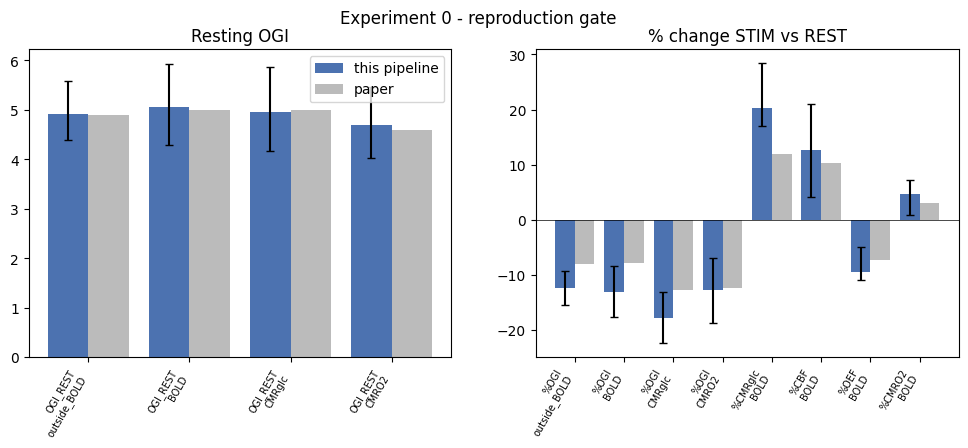

In [12]:
stage("STAGE 13 - reproduction gate")
def mean_ci(x, n=N_BOOT, fn=np.mean):
    x = np.asarray(x, float); x = x[np.isfinite(x)]
    if len(x) < 2: return (np.nan, np.nan, np.nan)
    b = fn(RNG.choice(x, (n, len(x)), replace=True), axis=1)
    return float(fn(x)), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))

PAPER = {  # values stated in the paper (main text); ROI/mask definitions approximated in MNI space
    ("OGI_REST", "outside_BOLD"): 4.9, ("pctOGI", "outside_BOLD"): -8.0,
    ("OGI_REST", "BOLD_mask_vis"): 5.0, ("pctOGI", "BOLD_mask_vis"): -7.9,
    ("OGI_REST", "CMRglc_mask_vis"): 5.0, ("pctOGI", "CMRglc_mask_vis"): -12.8,
    ("OGI_REST", "CMRO2_mask_vis"): 4.6, ("pctOGI", "CMRO2_mask_vis"): -12.4,
    ("pctCMRglc", "BOLD_mask_vis"): 11.86, ("pctCBF", "BOLD_mask_vis"): 10.24,
    ("pctOEF", "BOLD_mask_vis"): -7.27, ("pctCMRO2", "BOLD_mask_vis"): 3.13,
}
mv = mask_vals.pivot_table(index=["subject", "region"], columns="condition", values=PARAMS + ["OGI_vox"], dropna=False)
mv.columns = [f"{a}_{b}" for a, b in mv.columns]; mv = mv.reset_index()
gate = []
for (metric, region), ref in PAPER.items():
    d = mv[mv.region == region]
    if d.empty: continue
    if metric == "OGI_REST":
        vals = d["OGI_vox_REST"]
    else:
        p = metric.replace("pct", ""); p = "OGI_vox" if p == "OGI" else p
        vals = 100 * (d[f"{p}_STIM"] - d[f"{p}_REST"]) / d[f"{p}_REST"]
    est, lo, hi = mean_ci(vals) if metric.startswith(("OGI", "pctOGI")) else mean_ci(vals, fn=np.median)
    if metric == "OGI_REST":
        ok = abs(est - ref) <= 0.8
    else:
        ok = (np.sign(est) == np.sign(ref)) or abs(est - ref) < 3
    gate.append(dict(metric=metric, region=region, ours=est, ci_lo=lo, ci_hi=hi, paper=ref, n=len(vals), passed=bool(ok)))
# Table 1: REST cortical GM medians
for p, ref in TABLE1.items():
    if p in PARAMS:
        v = mv[mv.region == "cortex"][f"{p}_REST"]
        est, lo, hi = mean_ci(v, fn=np.median)
        gate.append(dict(metric=f"{p}_REST_GM_median", region="cortex", ours=est, ci_lo=lo, ci_hi=hi, paper=ref,
                         n=len(v), passed=bool(ref / 1.6 <= est <= ref * 1.6)))
gate = pd.DataFrame(gate)

# network differences in resting OGI (paper: F(6,66)=1.01, p=0.43) and % ROIs with significant ΔOGI (paper: 47%)
from statsmodels.stats.anova import AnovaRM
net_ogi = roi_wide.groupby(["subject", "network"]).OGI_REST.mean().reset_index()
complete = net_ogi.groupby("subject").network.nunique() == len(NETWORKS)
try:
    aov = AnovaRM(net_ogi[net_ogi.subject.isin(complete[complete].index)], "OGI_REST", "subject", within=["network"]).fit()
    F_, p_ = float(aov.anova_table["F Value"].iloc[0]), float(aov.anova_table["Pr > F"].iloc[0])
except Exception as e:
    F_, p_ = np.nan, np.nan; warn(f"RM-ANOVA failed: {e}")
roi_t = roi_wide.groupby("roi_id").delta_OGI.apply(lambda x: stats.ttest_1samp(x, 0).pvalue if x.notna().sum() > 2 else np.nan)
q = multipletests(roi_t.dropna(), method="fdr_bh")[1]
frac_sig = float((q < 0.05).mean())
gate = pd.concat([gate, pd.DataFrame([
    dict(metric="RM-ANOVA resting OGI across networks, p", region="cortex", ours=p_, paper=0.43, passed=bool(np.isnan(p_) or p_ > 0.01)),
    dict(metric="fraction of ROIs with FDR-significant ΔOGI", region="cortex", ours=frac_sig, paper=0.47, passed=True)])],
    ignore_index=True)
save_csv(gate, "06_reproduction_gate.csv")
print(gate.round(3).to_string(index=False))
key = gate[gate.metric.isin(["OGI_REST", "pctOGI"]) & (gate.region == "outside_BOLD")]
GATE_PASSED = bool(key.passed.all()) if len(key) else bool(gate.passed.all())
log(f"Reproduction gate passed: {GATE_PASSED}  (RM-ANOVA F={F_:.2f}, p={p_:.3f}; FDR-significant ΔOGI ROIs = {100*frac_sig:.0f}%)")
if not GATE_PASSED:
    msg = ("Reproduction gate FAILED: resting OGI or its change outside the BOLD mask is far from the paper. "
           "Likely causes: MNI-space approximation, the public STIM CMRO2 variant (desc-30perc), masking choices.")
    if STRICT_GATE: raise StageError(msg)
    warn(msg + " Continuing because STRICT_GATE=False - interpret ML results with this in mind.")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
g1 = gate[gate.metric == "OGI_REST"]; g2 = gate[gate.metric.str.startswith("pct")]
for a_, g, t in ((ax[0], g1, "Resting OGI"), (ax[1], g2, "% change STIM vs REST")):
    x = np.arange(len(g)); lbl = (g.metric + "\n" + g.region).str.replace("_mask_vis", "").str.replace("pct", "%")
    a_.bar(x - 0.2, g.ours, 0.4, yerr=[g.ours - g.ci_lo, g.ci_hi - g.ours], capsize=3, label="this pipeline", color="#4C72B0")
    a_.bar(x + 0.2, g.paper, 0.4, label="paper", color="#BBBBBB")
    a_.set_xticks(x); a_.set_xticklabels(lbl, rotation=60, ha="right", fontsize=7); a_.set_title(t); a_.axhline(0, c="k", lw=0.5)
ax[0].legend(); fig.suptitle("Experiment 0 - reproduction gate")
save_fig(fig, "fig01_reproduction_gate")

## 14–17. Leakage-safe nested LOSO engine (Ridge + baselines)
Template, scaling and α are learned from training subjects only; the inner loop also rebuilds the template without the inner validation subject.

In [13]:
stage("STAGE 14-17 - modelling engine")
SPECS = {
    "mean":             {"kind": "mean"},
    "template":         {"kind": "template"},
    "fixed_OGI":        {"kind": "fixed_ogi"},
    "CBF_only":         {"kind": "ridge", "feats": ["lr_CBF", "template"]},
    "CMRO2_only":       {"kind": "ridge", "feats": ["lr_CMRO2", "template"]},
    "full":             {"kind": "ridge", "feats": ["lr_CMRO2", "lr_CBF", "template"]},
    "full_no_template": {"kind": "ridge", "feats": ["lr_CMRO2", "lr_CBF"]},
}
PRIMARY = "full"

def ridge_fit(X, y, alpha):
    mu = X.mean(0); sd = X.std(0); sd[sd == 0] = 1.0
    Xs = (X - mu) / sd; ym = y.mean()
    coef = np.linalg.solve(Xs.T @ Xs + alpha * np.eye(X.shape[1]), Xs.T @ (y - ym))
    return {"mu": mu, "sd": sd, "coef": coef, "intercept": ym, "alpha": alpha}
def ridge_predict(m, X): return ((X - m["mu"]) / m["sd"]) @ m["coef"] + m["intercept"]

def make_data(df):
    """Arrays for the engine. roi_key can be ROI id or network name."""
    subj = df.subject.to_numpy(); keys = df.roi_key.to_numpy()
    uk = {k: i for i, k in enumerate(pd.unique(keys))}
    F = {c: df[c].to_numpy(float) for c in df.columns if c.startswith("lr_")}
    return {"df": df.reset_index(drop=True), "subj": subj, "roi": np.array([uk[k] for k in keys]), "n_roi": len(uk),
            "rest": df.condition.to_numpy() == "REST", "y": df.y.to_numpy(float), "F": F}

def template_of(D, tr):
    s = np.bincount(D["roi"][tr], weights=D["y"][tr], minlength=D["n_roi"])
    c = np.bincount(D["roi"][tr], minlength=D["n_roi"]).astype(float)
    t = np.full(D["n_roi"], np.nan); t[c > 0] = s[c > 0] / c[c > 0]; return t

def design(D, t, idx, feats):
    return np.column_stack([t[D["roi"][idx]] if f == "template" else D["F"][f][idx] for f in feats])

def fit(spec, D, tr, alpha=None):
    t = template_of(D, tr); k = spec["kind"]
    if k == "mean": return {"kind": k, "t": t, "mean": float(D["y"][tr].mean())}
    if k == "template": return {"kind": k, "t": t}
    if k == "fixed_ogi": return {"kind": k, "t": t, "c": float(np.mean(D["y"][tr] - D["F"]["lr_CMRO2"][tr]))}
    m = ridge_fit(design(D, t, tr, spec["feats"]), D["y"][tr], alpha); m.update(kind="ridge", t=t, feats=spec["feats"]); return m

def predict(m, D, idx):
    k = m["kind"]
    if k == "mean": return np.full(idx.sum(), m["mean"])
    if k == "template": return m["t"][D["roi"][idx]]
    if k == "fixed_ogi": return D["F"]["lr_CMRO2"][idx] + m["c"]
    return ridge_predict(m, design(D, m["t"], idx, m["feats"]))

def select_alpha(spec, D, train_subjects):
    """Inner LOSO on training subjects only; template recomputed without the inner validation subject."""
    scores = {a: [] for a in ALPHAS}
    for v in train_subjects:
        tr = D["rest"] & np.isin(D["subj"], [x for x in train_subjects if x != v])
        va = D["rest"] & (D["subj"] == v)
        t = template_of(D, tr); va = va & np.isfinite(t[D["roi"]])
        Xtr, ytr = design(D, t, tr, spec["feats"]), D["y"][tr]; Xva = design(D, t, va, spec["feats"])
        for a in ALPHAS:
            scores[a].append(np.mean(np.abs(ridge_predict(ridge_fit(Xtr, ytr, a), Xva) - D["y"][va])))
    mean_sc = {a: float(np.mean(s)) for a, s in scores.items()}
    return min(ALPHAS, key=lambda a: (mean_sc[a], -a)), mean_sc

def nested_loso(D, specs, subjects, keep_models=True):
    out, models, alpha_log = [], {}, []
    for s in subjects:
        train_subjects = [x for x in subjects if x != s]
        tr = D["rest"] & np.isin(D["subj"], train_subjects)            # REST rows of training subjects only
        t = template_of(D, tr)
        te = (D["subj"] == s) & np.isfinite(t[D["roi"]])                # held-out subject: REST and STIM rows
        assert not np.any(tr & (D["subj"] == s)), "leakage: held-out subject in training rows"
        for name, spec in specs.items():
            alpha, sc = (select_alpha(spec, D, train_subjects) if spec["kind"] == "ridge" else (None, None))
            m = fit(spec, D, tr, alpha)
            p = predict(m, D, te)
            part = D["df"].loc[te, ["subject", "roi_key", "condition", "y"]].copy()
            part["template"] = t[D["roi"][te]]; part["pred"] = p; part["model"] = name; part["fold"] = s; part["alpha"] = alpha
            out.append(part)
            if keep_models: models[(name, s)] = m
            if sc: alpha_log.append({"model": name, "fold": s, "alpha": alpha, **{f"innerMAE_a{a}": v for a, v in sc.items()}})
    return pd.concat(out, ignore_index=True), models, pd.DataFrame(alpha_log)

def subject_metrics(pred):
    """Per held-out subject, REST rows only; R2_vs_template uses the same rows' template predictions."""
    rows = []
    r = pred[pred.condition == "REST"]
    k = "roi_key" if "roi_key" in r.columns else "roi_id"
    tmpl = r[r.model == "template"].set_index(["fold", k]).pred.rename("tpred")
    for (mname, s), g in r.groupby(["model", "fold"]):
        g = g.join(tmpl, on=["fold", k])
        e = g.pred - g.y; et = g.tpred - g.y
        rows.append(dict(model=mname, subject=s, n_roi=len(g),
                         pearson_r=stats.pearsonr(g.pred, g.y)[0] if np.ptp(g.pred) > 1e-12 else np.nan,
                         spearman_rho=stats.spearmanr(g.pred, g.y)[0] if np.ptp(g.pred) > 1e-12 else np.nan,
                         MAE=float(np.mean(np.abs(e))), RMSE=float(np.sqrt(np.mean(e**2))),
                         R2_vs_template=float(1 - np.sum(e**2) / np.sum(et**2)),
                         R2_within_subject=float(1 - np.sum(e**2) / np.sum((g.y - g.y.mean())**2))))
    return pd.DataFrame(rows)
print("engine ready")


STAGE 14-17 - modelling engine
engine ready


## 15–18. Experiment 1 — nested LOSO on REST, all models; save fold-wise predictions and models

In [14]:
stage("STAGE 15-18 - Experiment 1")
df_m = roi_long[roi_long.subject.isin(PAIRED)].assign(roi_key=lambda d: d.roi_id).copy()
need = ["y", "lr_CMRO2", "lr_CBF"]
df_m = df_m.dropna(subset=need).reset_index(drop=True)
D1 = make_data(df_m)
t0 = time.time()
pred1, models1, alpha1 = nested_loso(D1, SPECS, PAIRED)
log(f"nested LOSO finished in {time.time()-t0:.1f}s; {pred1.fold.nunique()} outer folds x {len(SPECS)} models")
pred1 = pred1.rename(columns={"roi_key": "roi_id"}).merge(roi_info[["roi_id", "roi_name", "network"]], on="roi_id")
save_csv(pred1, "07_exp1_foldwise_predictions_REST_and_STIM.csv"); save_csv(alpha1, "07_exp1_inner_alpha_selection.csv")

# equivalence check: numpy ridge == sklearn StandardScaler+Ridge on fold 1
from sklearn.pipeline import make_pipeline; from sklearn.preprocessing import StandardScaler; from sklearn.linear_model import Ridge
s0 = PAIRED[0]; m0 = models1[(PRIMARY, s0)]
tr0 = D1["rest"] & (D1["subj"] != s0)
sk = make_pipeline(StandardScaler(), Ridge(alpha=m0["alpha"])).fit(design(D1, m0["t"], tr0, m0["feats"]), D1["y"][tr0])
te0 = (D1["subj"] == s0) & np.isfinite(m0["t"][D1["roi"]])
assert np.allclose(sk.predict(design(D1, m0["t"], te0, m0["feats"])), predict(m0, D1, te0), atol=1e-8)
log("numpy ridge matches scikit-learn Pipeline(StandardScaler, Ridge) exactly")

coef_rows = []
for (name, s), m in models1.items():
    if m["kind"] == "ridge":
        for f, c_std, sd in zip(m["feats"], m["coef"], m["sd"]):
            coef_rows.append(dict(model=name, fold=s, feature=f, alpha=m["alpha"], coef_standardized=c_std, coef_raw=c_std / sd))
    elif m["kind"] == "fixed_ogi":
        coef_rows.append(dict(model=name, fold=s, feature="offset_c", coef_raw=m["c"]))
coefs = pd.DataFrame(coef_rows); save_csv(coefs, "08_exp1_coefficients_by_fold.csv")
joblib.dump({f"{k[0]}|{k[1]}": v for k, v in models1.items()}, os.path.join(RESULTS_DIR, "models", "exp1_models_by_fold.joblib"))
save_json({f"{k[0]}|{k[1]}": {kk: vv for kk, vv in v.items() if kk != "t"} for k, v in models1.items()},
          "exp1_models_by_fold.json", folder="models")
print(coefs[coefs.model == PRIMARY].groupby("feature")[["coef_raw", "coef_standardized"]].agg(["mean", "std", "min", "max"]).round(3))


STAGE 15-18 - Experiment 1
[INFO] nested LOSO finished in 1.3s; 12 outer folds x 7 models
[INFO] numpy ridge matches scikit-learn Pipeline(StandardScaler, Ridge) exactly
         coef_raw                      coef_standardized                     
             mean    std    min    max              mean    std    min    max
feature                                                                      
lr_CBF      0.049  0.010  0.035  0.063             0.008  0.002  0.006  0.010
lr_CMRO2    0.062  0.004  0.052  0.067             0.012  0.001  0.010  0.013
template    0.840  0.044  0.793  0.895             0.073  0.004  0.068  0.078


## 19. Metrics: Pearson r, Spearman ρ, MAE, RMSE, R² vs template (per held-out subject, bootstrap CIs, Wilcoxon)

In [15]:
stage("STAGE 19 - metrics")
met1 = subject_metrics(pred1)
save_csv(met1, "09_exp1_metrics_per_subject.csv")
summ = []
for mname, g in met1.groupby("model"):
    row = {"model": mname, "n_subjects": len(g)}
    for col in ["pearson_r", "spearman_rho", "MAE", "RMSE", "R2_vs_template", "R2_within_subject"]:
        est, lo, hi = mean_ci(g[col], fn=np.median); row.update({f"{col}_median": est, f"{col}_lo": lo, f"{col}_hi": hi})
    summ.append(row)
summ = pd.DataFrame(summ).set_index("model").loc[list(SPECS)].reset_index()
# paired tests against the template and fixed-OGI baselines
pv = met1.pivot(index="subject", columns="model", values="pearson_r"); mae = met1.pivot(index="subject", columns="model", values="MAE")
for ref in ["template", "fixed_OGI"]:
    summ[f"median_delta_r_vs_{ref}"] = [float(np.median(pv[m] - pv[ref])) for m in summ.model]
    summ[f"wilcoxon_p_r_greater_than_{ref}"] = [float(stats.wilcoxon(pv[m] - pv[ref], alternative="greater").pvalue)
                                                 if m != ref and (pv[m] - pv[ref]).abs().sum() > 0 else np.nan for m in summ.model]
    summ[f"wilcoxon_p_MAE_less_than_{ref}"] = [float(stats.wilcoxon(mae[m] - mae[ref], alternative="less").pvalue)
                                                if m != ref and (mae[m] - mae[ref]).abs().sum() > 0 else np.nan for m in summ.model]
save_csv(summ, "10_exp1_model_summary.csv")
show = ["model", "pearson_r_median", "pearson_r_lo", "pearson_r_hi", "spearman_rho_median", "MAE_median", "RMSE_median",
        "R2_vs_template_median", "median_delta_r_vs_template", "wilcoxon_p_r_greater_than_template"]
print(summ[show].round(4).to_string(index=False))

# identification (G1): does the held-out subject's predicted individual pattern match their own observed pattern best?
r_ = pred1[(pred1.condition == "REST") & (pred1.model == PRIMARY)]
obs = roi_long[roi_long.condition == "REST"].pivot(index="roi_id", columns="subject", values="y")
hits, ranks = [], []
for s, g in r_.groupby("fold"):
    g = g.set_index("roi_id"); dev_pred = g.pred - g.template
    cors = {j: np.corrcoef(dev_pred, (obs.loc[g.index, j] - g.template))[0, 1]
            for j in PAIRED if obs.loc[g.index, j].notna().all()}
    order = sorted(cors, key=cors.get, reverse=True); ranks.append(order.index(s) + 1); hits.append(order[0] == s)
ID_ACC = float(np.mean(hits))
log(f"Identification accuracy (individual pattern) = {ID_ACC:.2f} (chance = {1/len(PAIRED):.2f}); median rank of own map = {np.median(ranks)}")
save_csv(pd.DataFrame({"subject": sorted(r_.fold.unique()), "own_rank": ranks, "hit": hits}), "11_exp1_identification.csv")


STAGE 19 - metrics
           model  pearson_r_median  pearson_r_lo  pearson_r_hi  spearman_rho_median  MAE_median  RMSE_median  R2_vs_template_median  median_delta_r_vs_template  wilcoxon_p_r_greater_than_template
            mean               NaN           NaN           NaN                  NaN      0.0730       0.0997                -2.4917                         NaN                                 NaN
        template            0.8739        0.8262        0.8924               0.8281      0.0379       0.0473                 0.0000                      0.0000                                 NaN
       fixed_OGI            0.5055        0.4526        0.5772               0.4220      0.1374       0.1724               -11.6353                     -0.3719                              1.0000
        CBF_only            0.8800        0.8381        0.8934               0.8385      0.0378       0.0483                 0.0866                      0.0086                              0.0461


'/content/drive/MyDrive/PET_MRI/Results/tables/11_exp1_identification.csv'

## 19b. Coupling slope: mixed models and measurement-error sensitivity (REST)

In [16]:
stage("STAGE 19b - coupling slope")
import statsmodels.formula.api as smf
rest = df_m[df_m.condition == "REST"].copy(); rest["roi_c"] = rest.roi_id.astype(str)
mm_rows = []
for label, formula, re_f in [("spatial coupling (no ROI effects)", "y ~ lr_CMRO2 + lr_CBF", "~lr_CMRO2"),
                             ("individual coupling (ROI fixed effects)", "y ~ lr_CMRO2 + lr_CBF + C(roi_c)", "1")]:
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            fitm = smf.mixedlm(formula, rest, groups=rest["subject"], re_formula=re_f).fit(reml=True, method="lbfgs")
        for term in ["lr_CMRO2", "lr_CBF"]:
            b, se = fitm.params[term], fitm.bse[term]
            mm_rows.append(dict(model=label, term=term, coef=b, se=se, ci_lo=b - 1.96 * se, ci_hi=b + 1.96 * se,
                                p_vs_0=2 * stats.norm.sf(abs(b / se)),
                                p_vs_OGI_assumption=2 * stats.norm.sf(abs((b - (1 if term == "lr_CMRO2" else 0)) / se))))
    except Exception as e:
        warn(f"mixed model '{label}' failed: {e}")
# errors-in-variables sensitivity: OLS vs orthogonal (TLS) slope of within-subject-centred lr_CMRglc on lr_CMRO2
c = rest.copy()
for col in ["y", "lr_CMRO2"]: c[col] = c[col] - c.groupby("subject")[col].transform("mean")
x, y = c.lr_CMRO2.to_numpy(), c.y.to_numpy()
sxx, syy, sxy = np.var(x), np.var(y), np.cov(x, y, bias=True)[0, 1]
ols = sxy / sxx; tls = (syy - sxx + np.sqrt((syy - sxx) ** 2 + 4 * sxy ** 2)) / (2 * sxy)
mm_rows += [dict(model="pooled within-subject OLS", term="lr_CMRO2", coef=ols),
            dict(model="pooled within-subject TLS (Deming, ratio 1)", term="lr_CMRO2", coef=tls)]
COUPLING = pd.DataFrame(mm_rows); save_csv(COUPLING, "12_coupling_slopes.csv")
print(COUPLING.round(4).to_string(index=False))


STAGE 19b - coupling slope
                                      model     term   coef     se  ci_lo  ci_hi  p_vs_0  p_vs_OGI_assumption
          spatial coupling (no ROI effects) lr_CMRO2 0.1344 0.0182 0.0987 0.1700     0.0                  0.0
          spatial coupling (no ROI effects)   lr_CBF 0.2304 0.0178 0.1956 0.2653     0.0                  0.0
    individual coupling (ROI fixed effects) lr_CMRO2 0.0793 0.0121 0.0556 0.1030     0.0                  0.0
    individual coupling (ROI fixed effects)   lr_CBF 0.1379 0.0197 0.0993 0.1765     0.0                  0.0
                  pooled within-subject OLS lr_CMRO2 0.2542    NaN    NaN    NaN     NaN                  NaN
pooled within-subject TLS (Deming, ratio 1) lr_CMRO2 0.3050    NaN    NaN    NaN     NaN                  NaN


## 19c. Subject-pairing permutation test (checkpointed). Null: mqBOLD maps of subject π(s) paired with CMRglc of subject s

In [17]:
stage("STAGE 19c - permutation test")
PERM_SPECS = {"template": SPECS["template"], PRIMARY: SPECS[PRIMARY]}
def stat_delta_r(D, subjects):
    p, _, _ = nested_loso(D, PERM_SPECS, subjects, keep_models=False)
    p = p[p.condition == "REST"]
    r = {(m_, f_): np.corrcoef(g.pred, g.y)[0, 1] for (m_, f_), g in p.groupby(["model", "fold"])}
    return float(np.median([r[(PRIMARY, s)] - r[("template", s)] for s in subjects]))

rest_only = df_m[df_m.condition == "REST"].reset_index(drop=True)
OBS_STAT = stat_delta_r(make_data(rest_only), PAIRED)
feat_cols = [c for c in rest_only.columns if c.startswith("lr_") and c != "lr_CMRglc"]
import hashlib
_fp_df = rest_only[["subject", "roi_id", "y"] + feat_cols].sort_values(["subject", "roi_id"]).round(10)
DATA_FP = hashlib.sha256(pd.util.hash_pandas_object(_fp_df, index=False).values.tobytes()).hexdigest()[:12]
# null checkpoint is keyed to the extraction version AND the exact data: an old null from other data is never reused
perm_file = os.path.join(RESULTS_DIR, "tables", f"13_permutation_null_{EXTRACT_VERSION}_{DATA_FP}.csv")
null = pd.read_csv(perm_file).stat.tolist() if os.path.exists(perm_file) else []
log(f"observed median Δr (full - template) = {OBS_STAT:.4f}; {len(null)} permutations already on disk ({os.path.basename(perm_file)})")
def derangement(n, rng):
    while True:
        p = rng.permutation(n)
        if not np.any(p == np.arange(n)): return p
prng = np.random.default_rng(SEED + len(null)); t0 = time.time()
for i in range(len(null), N_PERM):
    perm = derangement(len(PAIRED), prng)
    parts = []
    for s, s_src in zip(PAIRED, np.array(PAIRED)[perm]):
        tgt = rest_only[rest_only.subject == s].drop(columns=feat_cols)
        src = rest_only[rest_only.subject == s_src][["roi_id"] + feat_cols]
        parts.append(tgt.merge(src, on="roi_id"))
    null.append(stat_delta_r(make_data(pd.concat(parts, ignore_index=True)), PAIRED))
    if (i + 1) % 25 == 0 or i + 1 == N_PERM:
        pd.DataFrame({"stat": null}).to_csv(perm_file, index=False)
        print(f"  {i+1}/{N_PERM} permutations, {time.time()-t0:.0f}s elapsed this session")
null = np.array(null)
PERM_P = float((1 + np.sum(null >= OBS_STAT)) / (1 + len(null)))
log(f"Subject-pairing permutation p = {PERM_P:.4f} (N={len(null)})")
SAVED.append(perm_file)


STAGE 19c - permutation test
[INFO] observed median Δr (full - template) = 0.0170; 0 permutations already on disk (13_permutation_null_v2_cmrglc_stim_eq_baseline_plus_checker_dd9cdcd13b18.csv)
  25/500 permutations, 9s elapsed this session
  50/500 permutations, 17s elapsed this session
  75/500 permutations, 26s elapsed this session
  100/500 permutations, 46s elapsed this session
  125/500 permutations, 55s elapsed this session
  150/500 permutations, 64s elapsed this session
  175/500 permutations, 72s elapsed this session
  200/500 permutations, 81s elapsed this session
  225/500 permutations, 89s elapsed this session
  250/500 permutations, 98s elapsed this session
  275/500 permutations, 107s elapsed this session
  300/500 permutations, 115s elapsed this session
  325/500 permutations, 124s elapsed this session
  350/500 permutations, 132s elapsed this session
  375/500 permutations, 143s elapsed this session
  400/500 permutations, 152s elapsed this session
  425/500 permutatio

## 20–22. Experiment 2 — apply each REST-trained outer-fold model to the held-out subject's STIM data; D = Δy − Δŷ

In [18]:
stage("STAGE 20-22 - Experiment 2: coupling deviation D")
pr = pred1[pred1.model != "mean"].pivot_table(index=["model", "fold", "roi_id"], columns="condition", values=["y", "pred"], dropna=False).dropna()
pr.columns = [f"{a}_{b}" for a, b in pr.columns]
dtab = pr.reset_index().rename(columns={"fold": "subject"}).merge(roi_info[["roi_id", "roi_name", "network"]], on="roi_id")
dtab["dy_obs"] = dtab.y_STIM - dtab.y_REST
dtab["dy_pred"] = dtab.pred_STIM - dtab.pred_REST
dtab["D"] = dtab.dy_obs - dtab.dy_pred
dtab = dtab.merge(roi_wide[["subject", "roi_id", "dlog_OGI", "pct_OGI"]], on=["subject", "roi_id"], how="left")
# sanity: for the fixed-OGI model D must equal -Δlog(OGI) exactly
fx = dtab[dtab.model == "fixed_OGI"]
err = float(np.nanmax(np.abs(fx.D + fx.dlog_OGI)))
if err > 1e-6:
    raise StageError(f"fixed-OGI D != -dlog(OGI) (max abs diff {err:.2e}); feature construction is inconsistent.")
log(f"check passed: fixed-OGI D equals -Δlog(OGI) (max diff {err:.1e})")
save_csv(dtab, "14_exp2_D_by_subject_roi.csv")

def summarise(d, by):
    rows = []
    for key, g in d.groupby(by):
        key = key if isinstance(key, tuple) else (key,)
        r = dict(zip(by, key))
        for col in ["D", "dy_obs", "dy_pred"]:
            per_sub = g.groupby("subject")[col].mean()
            est, lo, hi = mean_ci(per_sub)
            nz = per_sub[per_sub != 0]
            p = float(stats.wilcoxon(nz).pvalue) if len(nz) >= 5 else np.nan
            r.update({f"{col}_mean": est, f"{col}_lo": lo, f"{col}_hi": hi, f"{col}_p": p})
        r["n_subjects"] = g.subject.nunique(); rows.append(r)
    out = pd.DataFrame(rows)
    for mname, idx in out.groupby("model").groups.items():
        for col in ["D", "dy_obs", "dy_pred"]:
            pp = out.loc[idx, f"{col}_p"]; ok = pp.notna()
            out.loc[pp[ok].index, f"{col}_q_fdr"] = multipletests(pp[ok], method="fdr_bh")[1] if ok.any() else np.nan
    return out

net_D = summarise(dtab, ["model", "network"])
net_D["network"] = pd.Categorical(net_D.network, NETWORKS); net_D = net_D.sort_values(["model", "network"])
vis_split = summarise(dtab.assign(zone=np.where(dtab.network == "Vis", "visual", "non-visual")), ["model", "zone"])
roi_D = summarise(dtab, ["model", "roi_id"]).merge(roi_info, on="roi_id")
save_csv(net_D, "15_exp2_D_by_network.csv"); save_csv(vis_split, "15_exp2_D_visual_vs_nonvisual.csv"); save_csv(roi_D, "16_exp2_D_by_roi.csv")
cols = ["network", "D_mean", "D_lo", "D_hi", "D_q_fdr", "dy_obs_mean", "dy_pred_mean", "n_subjects"]
print("PRIMARY model:\n", net_D[net_D.model == PRIMARY][cols].round(4).to_string(index=False))
print("\nVisual vs non-visual:\n", vis_split[vis_split.model.isin([PRIMARY, "fixed_OGI"])][["model", "zone"] + cols[1:]].round(4).to_string(index=False))
m_roi = roi_D[roi_D.model == PRIMARY]
log(f"{PRIMARY}: {int((m_roi.D_q_fdr < 0.05).sum())}/{len(m_roi)} ROIs with FDR-significant D "
    f"({int(((m_roi.D_q_fdr < 0.05) & (m_roi.D_mean > 0)).sum())} positive)")


STAGE 20-22 - Experiment 2: coupling deviation D
[INFO] check passed: fixed-OGI D equals -Δlog(OGI) (max diff 4.4e-16)
PRIMARY model:
     network  D_mean   D_lo   D_hi  D_q_fdr  dy_obs_mean  dy_pred_mean  n_subjects
        Vis  0.1452 0.1248 0.1670   0.0005       0.1459        0.0007          12
     SomMot  0.1158 0.0976 0.1356   0.0005       0.1105       -0.0052          12
   DorsAttn  0.1131 0.0872 0.1414   0.0005       0.1079       -0.0052          12
SalVentAttn  0.1132 0.0836 0.1441   0.0005       0.1078       -0.0055          12
     Limbic  0.1142 0.0779 0.1523   0.0005       0.1066       -0.0076          12
       Cont  0.0903 0.0651 0.1163   0.0005       0.0837       -0.0066          12
    Default  0.0884 0.0713 0.1058   0.0005       0.0833       -0.0051          12

Visual vs non-visual:
     model       zone  D_mean   D_lo   D_hi  D_q_fdr  dy_obs_mean  dy_pred_mean  n_subjects
fixed_OGI non-visual  0.1528 0.1171 0.1886   0.0005       0.0972       -0.0556          12
fi

## 22b. Sensitivity: + CBV (subjects with CBV in both conditions) and network-level (7 Yeo networks) models

In [19]:
stage("STAGE 22b - sensitivity analyses")
SENS = {}
if "lr_CBV" in roi_long.columns and len(CBV_SUBJECTS) >= 6:
    d_cbv = roi_long[roi_long.subject.isin(CBV_SUBJECTS)].dropna(subset=["y", "lr_CMRO2", "lr_CBF", "lr_CBV"]).assign(roi_key=lambda d: d.roi_id)
    specs_cbv = {"template": SPECS["template"], "full": SPECS["full"],
                 "full_plus_CBV": {"kind": "ridge", "feats": ["lr_CMRO2", "lr_CBF", "lr_CBV", "template"]}}
    p_cbv, _, _ = nested_loso(make_data(d_cbv.reset_index(drop=True)), specs_cbv, CBV_SUBJECTS, keep_models=False)
    m_cbv = subject_metrics(p_cbv); save_csv(m_cbv, "17_sens_CBV_metrics_per_subject.csv")
    SENS["CBV"] = m_cbv.groupby("model")[["pearson_r", "MAE", "R2_vs_template"]].median().round(4)
    print(f"CBV subset (n={len(CBV_SUBJECTS)}):\n", SENS["CBV"])
else:
    warn("CBV sensitivity skipped (CBV maps missing or fewer than 6 subjects).")
net_long = (roi_long[roi_long.subject.isin(PAIRED)].groupby(["subject", "network", "condition"])[["y", "lr_CMRO2", "lr_CBF"]]
            .mean().reset_index().rename(columns={"network": "roi_key"}))
p_net, _, _ = nested_loso(make_data(net_long), {k: SPECS[k] for k in ["template", "fixed_OGI", "full"]}, PAIRED, keep_models=False)
m_net = subject_metrics(p_net); save_csv(m_net, "17_sens_network_level_metrics_per_subject.csv")
SENS["network_level"] = m_net.groupby("model")[["pearson_r", "MAE", "R2_vs_template"]].median().round(4)
print("Network level (7 values per subject):\n", SENS["network_level"])


STAGE 22b - sensitivity analyses
CBV subset (n=11):
                pearson_r     MAE  R2_vs_template
model                                           
full              0.8764  0.0367          0.1506
full_plus_CBV     0.8744  0.0368          0.1475
template          0.8641  0.0369          0.0000
Network level (7 values per subject):
            pearson_r     MAE  R2_vs_template
model                                       
fixed_OGI     0.5664  0.0456         -8.4425
full          0.9277  0.0167          0.1231
template      0.9125  0.0185          0.0000


## 23. Figures


STAGE 23 - figures


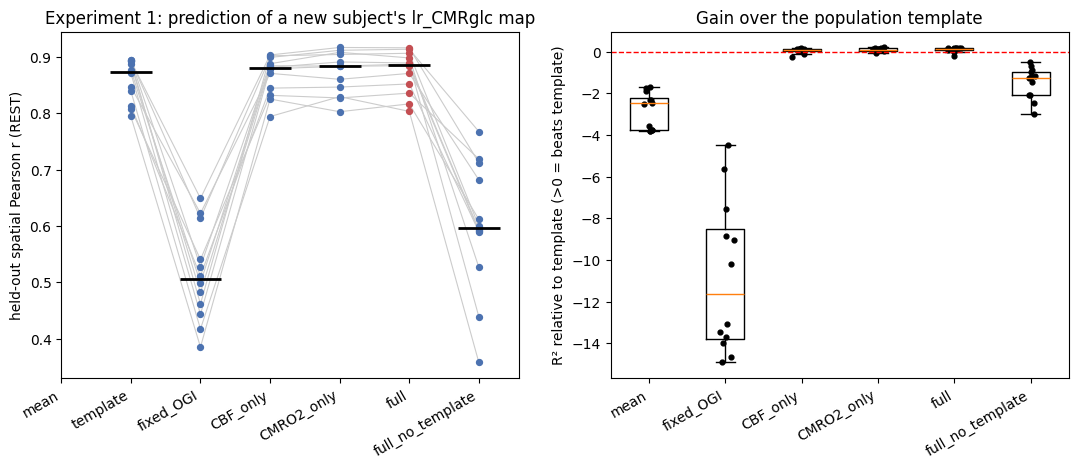

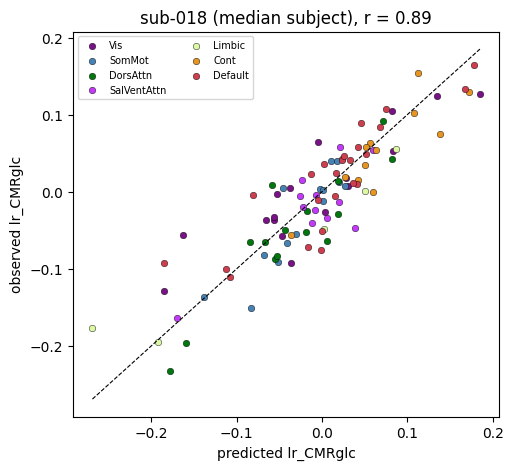

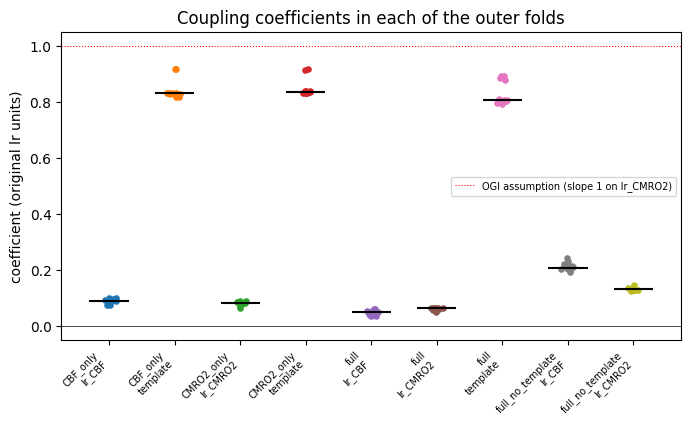

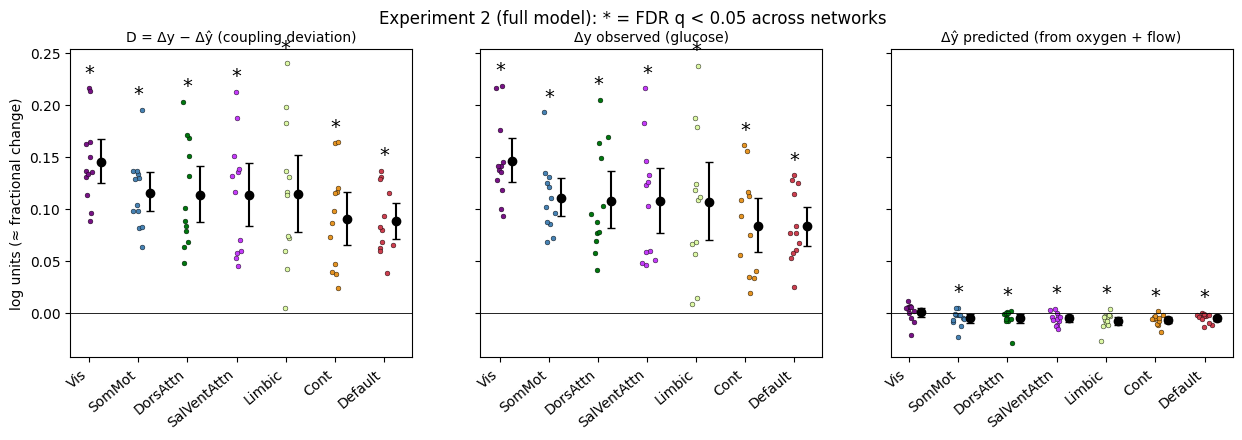

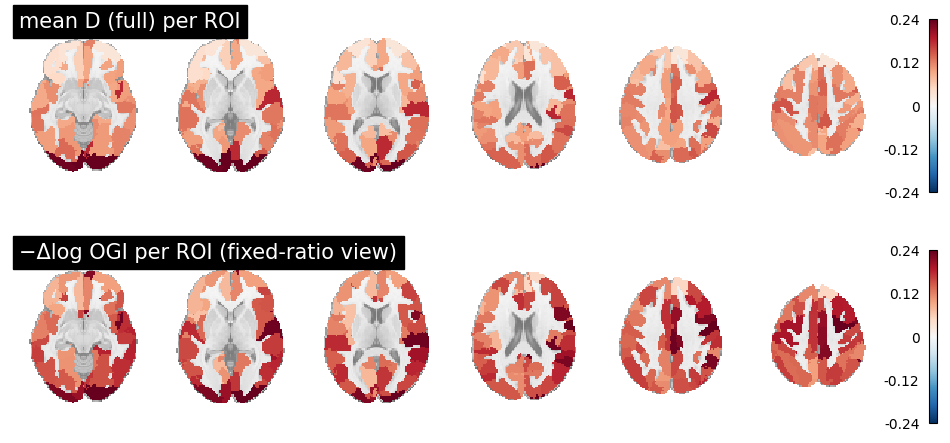

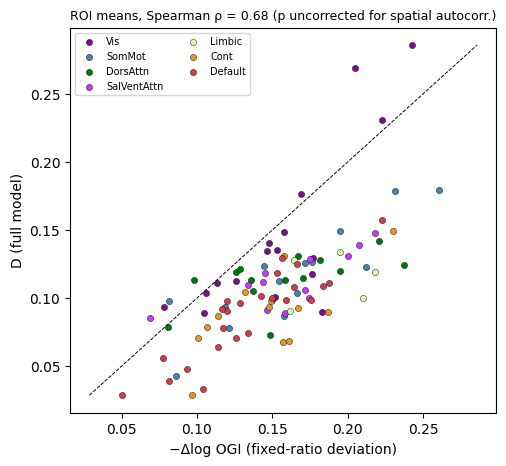

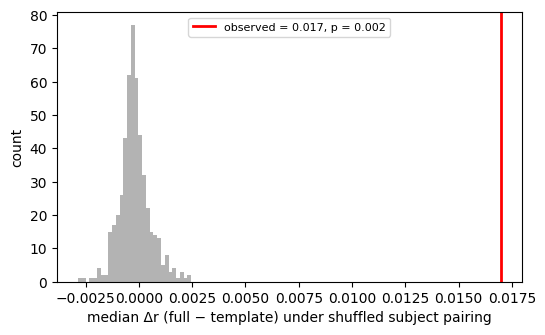

In [20]:
stage("STAGE 23 - figures")
NET_COL = dict(zip(NETWORKS, ["#781286", "#4682B4", "#00760E", "#C43AFA", "#DCF8A4", "#E69422", "#CD3E4E"]))
order = list(SPECS)

# Fig 2: per-subject spatial r by model (paired lines) + R2 vs template
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
pv = met1.pivot(index="subject", columns="model", values="pearson_r")[order]
for s, row in pv.iterrows(): ax[0].plot(range(len(order)), row.values, c="0.8", lw=0.8, zorder=1)
for i, mname in enumerate(order):
    ax[0].scatter(np.full(len(pv), i), pv[mname], s=18, zorder=2, c="#C44E52" if mname == PRIMARY else "#4C72B0")
    ax[0].hlines(pv[mname].median(), i - 0.3, i + 0.3, color="k", lw=2, zorder=3)
ax[0].set_xticks(range(len(order))); ax[0].set_xticklabels(order, rotation=30, ha="right"); ax[0].set_ylabel("held-out spatial Pearson r (REST)")
ax[0].set_title("Experiment 1: prediction of a new subject's lr_CMRglc map")
r2 = met1.pivot(index="subject", columns="model", values="R2_vs_template")[[m for m in order if m not in ("template",)]]
ax[1].boxplot([r2[c].dropna() for c in r2.columns], showfliers=False)
for i, c in enumerate(r2.columns): ax[1].scatter(np.full(len(r2), i + 1) + RNG.normal(0, 0.04, len(r2)), r2[c], s=12, c="k")
ax[1].axhline(0, c="r", lw=1, ls="--"); ax[1].set_xticks(range(1, len(r2.columns) + 1)); ax[1].set_xticklabels(r2.columns, rotation=30, ha="right")
ax[1].set_ylabel("R² relative to template (>0 = beats template)"); ax[1].set_title("Gain over the population template")
save_fig(fig, "fig02_exp1_model_comparison")

# Fig 3: observed vs predicted for the median subject (primary model)
med_s = met1[met1.model == PRIMARY].sort_values("pearson_r").iloc[len(PAIRED) // 2].subject
g = pred1[(pred1.model == PRIMARY) & (pred1.fold == med_s) & (pred1.condition == "REST")]
fig, ax = plt.subplots(figsize=(5.5, 5))
for n in NETWORKS:
    h = g[g.network == n]; ax.scatter(h.pred, h.y, s=22, c=NET_COL[n], edgecolor="k", lw=0.3, label=n)
lim = [min(g.pred.min(), g.y.min()), max(g.pred.max(), g.y.max())]; ax.plot(lim, lim, "k--", lw=0.8)
ax.set_xlabel("predicted lr_CMRglc"); ax.set_ylabel("observed lr_CMRglc")
ax.set_title(f"{med_s} (median subject), r = {np.corrcoef(g.pred, g.y)[0,1]:.2f}"); ax.legend(fontsize=7, ncol=2)
save_fig(fig, "fig03_exp1_observed_vs_predicted_median_subject")

# Fig 4: coefficients across the outer folds
cf = coefs[coefs.model.isin(["full", "CMRO2_only", "CBF_only", "full_no_template"])]
fig, ax = plt.subplots(figsize=(8, 4))
labels_ = []
for i, ((mname, f), h) in enumerate(cf.groupby(["model", "feature"])):
    ax.scatter(np.full(len(h), i) + RNG.normal(0, 0.05, len(h)), h.coef_raw, s=14); ax.hlines(h.coef_raw.median(), i - 0.3, i + 0.3, color="k")
    labels_.append(f"{mname}\n{f}")
ax.axhline(0, c="k", lw=0.5); ax.axhline(1, c="r", lw=0.8, ls=":", label="OGI assumption (slope 1 on lr_CMRO2)")
ax.set_xticks(range(len(labels_))); ax.set_xticklabels(labels_, rotation=45, ha="right", fontsize=7)
ax.set_ylabel("coefficient (original lr units)"); ax.set_title("Coupling coefficients in each of the outer folds"); ax.legend(fontsize=7)
save_fig(fig, "fig04_exp1_coefficients_across_folds")

# Fig 5: D by network with decomposition (primary model)
sub_net = dtab[dtab.model == PRIMARY].groupby(["subject", "network"])[["D", "dy_obs", "dy_pred"]].mean().reset_index()
nd = net_D[net_D.model == PRIMARY].set_index("network")
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a_, col, t in zip(ax, ["D", "dy_obs", "dy_pred"], ["D = Δy − Δŷ (coupling deviation)", "Δy observed (glucose)", "Δŷ predicted (from oxygen + flow)"]):
    for i, n in enumerate(NETWORKS):
        h = sub_net[sub_net.network == n][col]
        a_.scatter(np.full(len(h), i) + RNG.normal(0, 0.06, len(h)), h, s=12, c=NET_COL[n], edgecolor="k", lw=0.3)
        a_.errorbar(i + 0.25, nd.loc[n, f"{col}_mean"], yerr=[[nd.loc[n, f"{col}_mean"] - nd.loc[n, f"{col}_lo"]], [nd.loc[n, f"{col}_hi"] - nd.loc[n, f"{col}_mean"]]], fmt="o", c="k", capsize=3)
        qv = nd.loc[n, f"{col}_q_fdr"]
        if np.isfinite(qv) and qv < 0.05: a_.text(i, h.max() + 0.01, "*", ha="center", fontsize=14)
    a_.axhline(0, c="k", lw=0.6); a_.set_xticks(range(len(NETWORKS))); a_.set_xticklabels(NETWORKS, rotation=40, ha="right"); a_.set_title(t, fontsize=10)
ax[0].set_ylabel("log units (≈ fractional change)"); fig.suptitle(f"Experiment 2 ({PRIMARY} model): * = FDR q < 0.05 across networks")
save_fig(fig, "fig05_exp2_D_by_network_decomposition")

# Fig 6: brain maps of mean D (primary) and -Δlog OGI per ROI
from nilearn import plotting
def roi_map(values):
    arr = np.zeros(ATL.shape, np.float32)
    for rid, v in values.items():
        if np.isfinite(v): arr[ATL == rid] = v
    return nib.Nifti1Image(arr, atlas_img.affine)
mean_D = dtab[dtab.model == PRIMARY].groupby("roi_id").D.mean()
mean_mdo = -dtab[dtab.model == PRIMARY].groupby("roi_id").dlog_OGI.mean()
vmax = float(np.nanpercentile(np.abs(np.r_[mean_D.values, mean_mdo.values]), 98))
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5))
plotting.plot_stat_map(roi_map(mean_D), display_mode="z", cut_coords=[-10, 0, 10, 20, 35, 50], cmap="RdBu_r", vmax=vmax,
                       symmetric_cbar=True, axes=ax[0], title=f"mean D ({PRIMARY}) per ROI", annotate=False, draw_cross=False)
plotting.plot_stat_map(roi_map(mean_mdo), display_mode="z", cut_coords=[-10, 0, 10, 20, 35, 50], cmap="RdBu_r", vmax=vmax,
                       symmetric_cbar=True, axes=ax[1], title="−Δlog OGI per ROI (fixed-ratio view)", annotate=False, draw_cross=False)
save_fig(fig, "fig06_exp2_D_brain_maps")

# Fig 7: D vs -Δlog OGI across ROIs (p uncorrected for spatial autocorrelation)
fig, ax = plt.subplots(figsize=(5.5, 5))
both = pd.DataFrame({"D": mean_D, "mdo": mean_mdo}).join(roi_info.set_index("roi_id").network)
for n in NETWORKS:
    h = both[both.network == n]; ax.scatter(h.mdo, h.D, s=20, c=NET_COL[n], edgecolor="k", lw=0.3, label=n)
rr, pp = stats.spearmanr(both.mdo, both.D, nan_policy="omit")
lim = [both[["D", "mdo"]].min().min(), both[["D", "mdo"]].max().max()]; ax.plot(lim, lim, "k--", lw=0.7)
ax.set_xlabel("−Δlog OGI (fixed-ratio deviation)"); ax.set_ylabel(f"D ({PRIMARY} model)")
ax.set_title(f"ROI means, Spearman ρ = {rr:.2f} (p uncorrected for spatial autocorr.)", fontsize=9); ax.legend(fontsize=7, ncol=2)
save_fig(fig, "fig07_exp2_D_vs_OGI")

# Fig 8: permutation null
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(null, bins=30, color="0.7"); ax.axvline(OBS_STAT, c="r", lw=2, label=f"observed = {OBS_STAT:.3f}, p = {PERM_P:.3f}")
ax.set_xlabel("median Δr (full − template) under shuffled subject pairing"); ax.set_ylabel("count"); ax.legend(fontsize=8)
save_fig(fig, "fig08_permutation_null")

## 24–25. Save run summary and print final results

In [21]:
stage("STAGE 24-25 - final summary")
prim = summ.set_index("model").loc[PRIMARY]
vis_p = vis_split[vis_split.model == PRIMARY].set_index("zone")
summary = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "data_root": DATA_ROOT, "results_dir": RESULTS_DIR,
    "versions": {"nilearn": nilearn.__version__, "nibabel": nib.__version__, "sklearn": sklearn.__version__, "statsmodels": statsmodels.__version__},
    "config": {k: globals()[k] for k in ["ALPHAS", "MIN_VOX", "GM_PROB_THR", "USE_TSNR_MASK", "CBF_MAX", "OEF_MAX", "CBV_MAX",
                                          "APPLY_OGI_OUTLIER_RULE", "STIM_MQBOLD_DESC", "N_BOOT", "N_PERM", "SEED",
                                          "CMRGLC_STIM_DEF", "EXTRACT_VERSION"]},
    "subjects": {"paired": PAIRED, "n_paired": len(PAIRED), "cbv_subjects": CBV_SUBJECTS},
    "rois_per_subject": roi_long[roi_long.condition == "REST"].groupby("subject").size().to_dict(),
    "reproduction_gate_passed": GATE_PASSED,
    "reproduction_gate": gate.to_dict(orient="records"),
    "exp1_model_summary": summ.to_dict(orient="records"),
    "exp1_selected_alphas": alpha1[alpha1.model == PRIMARY].alpha.value_counts().to_dict() if len(alpha1) else {},
    "permutation": {"observed_median_delta_r": OBS_STAT, "p": PERM_P, "n_perm": int(len(null))},
    "identification_accuracy": ID_ACC, "identification_chance": 1 / len(PAIRED),
    "coupling_slopes": COUPLING.to_dict(orient="records"),
    "exp2_network_D_primary": net_D[net_D.model == PRIMARY].to_dict(orient="records"),
    "exp2_visual_vs_nonvisual": vis_split.to_dict(orient="records"),
    "sensitivity": {k: v.reset_index().to_dict(orient="records") for k, v in SENS.items()},
}
save_json(summary, "RUN_SUMMARY.json")
with open(os.path.join(RESULTS_DIR, "logs", f"run_log_{datetime.datetime.now():%Y%m%d_%H%M%S}.txt"), "w") as f:
    f.write("\n".join(LOG))

print("\n" + "#" * 90)
print("FINAL SUMMARY")
print("#" * 90)
print(f"Subjects: {len(PAIRED)} paired ({', '.join(PAIRED)}); CBV subset n={len(CBV_SUBJECTS)}")
print(f"ROIs per subject (after masking): {min(summary['rois_per_subject'].values())}-{max(summary['rois_per_subject'].values())}")
print(f"Reproduction gate passed: {GATE_PASSED}")
print(f"\nExperiment 1 (held-out REST, median over {len(PAIRED)} subjects [95% bootstrap CI]):")
for mname in order:
    r = summ.set_index("model").loc[mname]
    print(f"  {mname:17s} r = {r.pearson_r_median:.3f} [{r.pearson_r_lo:.3f}, {r.pearson_r_hi:.3f}]   "
          f"MAE = {r.MAE_median:.4f}   R2_vs_template = {r.R2_vs_template_median:.3f}")
print(f"  {PRIMARY} vs template: median Δr = {prim.median_delta_r_vs_template:.4f}, Wilcoxon p = {prim.wilcoxon_p_r_greater_than_template:.4f}, "
      f"subject-pairing permutation p = {PERM_P:.4f}")
print(f"  Identification accuracy = {ID_ACC:.2f} (chance {1/len(PAIRED):.2f})")
cs = COUPLING[COUPLING.term == "lr_CMRO2"]
for _, r in cs.iterrows():
    print(f"  slope lr_CMRglc~lr_CMRO2 [{r.model}]: {r.coef:.3f}" + (f" (95% CI {r.ci_lo:.3f} to {r.ci_hi:.3f}; p vs 1 = {r.p_vs_OGI_assumption:.4f})" if pd.notna(r.get("ci_lo", np.nan)) else ""))
print(f"\nExperiment 2 (D = Δy − Δŷ, {PRIMARY} model; mean over subjects [95% CI], FDR q):")
for _, r in net_D[net_D.model == PRIMARY].iterrows():
    print(f"  {r.network:12s} D = {r.D_mean:+.4f} [{r.D_lo:+.4f}, {r.D_hi:+.4f}] q = {r.D_q_fdr:.4f}   Δy = {r.dy_obs_mean:+.4f}   Δŷ = {r.dy_pred_mean:+.4f}")
for z in ["visual", "non-visual"]:
    if z in vis_p.index:
        r = vis_p.loc[z]; print(f"  {z:12s} D = {r.D_mean:+.4f} [{r.D_lo:+.4f}, {r.D_hi:+.4f}] p = {r.D_p:.4f}   Δy = {r.dy_obs_mean:+.4f}   Δŷ = {r.dy_pred_mean:+.4f}")
print(f"\nSaved {len(set(SAVED))} files under {RESULTS_DIR} (tables/, figures/, models/, cache/, logs/)")
print("Key files: tables/RUN_SUMMARY.json, tables/10_exp1_model_summary.csv, tables/15_exp2_D_by_network.csv, "
      "tables/07_exp1_foldwise_predictions_REST_and_STIM.csv, figures/fig02..fig08")


STAGE 24-25 - final summary

##########################################################################################
FINAL SUMMARY
##########################################################################################
Subjects: 12 paired (sub-001, sub-004, sub-007, sub-010, sub-011, sub-014, sub-015, sub-016, sub-017, sub-018, sub-019, sub-020); CBV subset n=11
ROIs per subject (after masking): 96-100
Reproduction gate passed: True

Experiment 1 (held-out REST, median over 12 subjects [95% bootstrap CI]):
  mean              r = nan [nan, nan]   MAE = 0.0730   R2_vs_template = -2.492
  template          r = 0.874 [0.826, 0.892]   MAE = 0.0379   R2_vs_template = 0.000
  fixed_OGI         r = 0.505 [0.453, 0.577]   MAE = 0.1374   R2_vs_template = -11.635
  CBF_only          r = 0.880 [0.838, 0.893]   MAE = 0.0378   R2_vs_template = 0.087
  CMRO2_only        r = 0.883 [0.838, 0.906]   MAE = 0.0356   R2_vs_template = 0.087
  full              r = 0.886 [0.844, 0.902]   MAE = 0.0361